This notebook contains the code which is to be used to acgieve path planning with traffic prediction.

Task -1 LayoutReader.py
Functionality
1. read .csv as numpy array
2. find all {obs, ava, shelf, dock}
3. define zones
3. define zonesDict[loc]=zone



New warehouse layout

Mounting the sahred drive to access the .csv file which has the layout of the map

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount("/content/gdrive")

Mounted at /content/gdrive


In [ ]:
%cd 
# !ls "/content/gdrive/Shared Drives/Winter Simulation 2021"
!ls "/content/gdrive/Shareddrives/Winter Simulation 2021"
!ls 

/root
 BusinessMeasurement.gsheet
'Copy_of_training_in_pieces_(1).ipynb'
 CPwrite.csv
 data_for_pathplanning_any.pkl
 data_for_pathplanning.pkl
 data_for_pathplanning_test_case.pkl
 data_for_testing100_1v_1t.pkl
 data_for_testing_1_vehicle.pkl
 data_for_testing.pkl
 data_for_training100000_1v_1t.pkl
 data_for_training100000_1vehicle.pkl
 data_for_training100000.pkl
 data_for_training10000_old.pkl
 data_for_training10000.pkl
 data_for_training10_1v_1t.pkl
 data_for_training150000_1v_1t.pkl
 data_for_training5000.pkl
 data_for_training.pkl
 filename1.csv
 filename1.gsheet
 filename.xlsx
 image1.png
 image2.png
 image_test_more_than_orequal1.png
 image_test_more_than_or_equal2.png
 image_test_more_than_orequal2.png
 image_test_more_than_or_equal3.png
 image_test_more_than_orequal3.png
 image_test.png
 image_zones.png
 Layout.gsheet
'Layout - Sheet1.csv'
 Layout_updated_1.csv
'Layout_updated_2021 (1).csv'
 Layout_updated_2021.csv
 Layout_updated.csv
 model_epoch
 model.pkl
 my_history_4_16

1.

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
data


array([[ -1.,  -1.,  -1., ...,  -1.,  -1.,  -1.],
       [ -1.,  50.,   0., ...,   0.,  50.,  -1.],
       [ -1.,   0., 200., ..., 100.,   0.,  -1.],
       ...,
       [ -1.,   0., 200., ..., 100.,   0.,  -1.],
       [ -1.,  50.,   0., ...,   0.,  50.,  -1.],
       [ -1.,  -1.,  -1., ...,  -1.,  -1.,  -1.]])

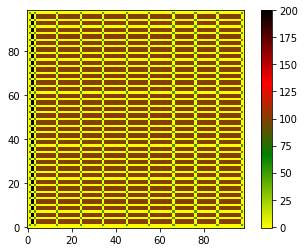

In [ ]:
from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['yellow','green','red','black'],
                                           256)

img2 = pyplot.imshow(data,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/Warehouse_layout.png")

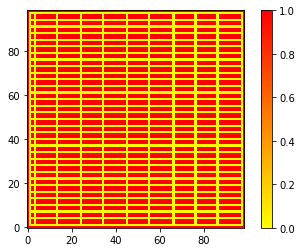

In [ ]:
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)
              



fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['yellow','red'],
                                           256)

img2 = pyplot.imshow(maze1,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/Warehouse_maze_seen_by_ASTAR.png")


define zones \\
define zonesDict[loc]=zone \\
A zone is between 2 junctions

In [ ]:
size_data=np.size(data)
shape_data=np.shape(data)
'''print(size_data)
print(shape_data)
print(data.shape)'''

def countX(lst, x):
    count = 0
    for el in lst:
      for ele in el:
        if (ele == x):
            count = count + 1
    return count

print('{} has occurred {} times'.format(50, countX(data, 50)))
print('{} has occurred {} times'.format(100, countX(data, 100)))
print('{} has occurred {} times'.format(200, countX(data, 200)))
print('{} has occurred {} times'.format(0, countX(data, 0)))
print('{} has occurred {} times'.format(-1, countX(data, -1)))

zones_dictionary={}
#New zoning 
#Involves labeling available free paths as zones 
#It can be noticed that there are vertical and horizontal free paths which make up the zones
#If a zone is enterd, it can be left only through the intersections 
zone = 0
zone1 = 1
zone2=1 
c50=0
c0=0
maze=np.array(data)
else_counter=0
for row in range (0,shape_data[0]-1) :
    for colm in range(0,shape_data[1]-1):
        if maze[row,colm]==50:
             else_counter=0
             zone=zone+1
             #zone1=zone1+1
             zones_dictionary[(row,colm)] = zone
             zone=zone+1
             c50=c50+1
        elif maze[row,colm]==0 and maze[row,colm+1]!=200 and maze[row,colm+1]!=100 and maze[row,colm+1]!=-1:
            #print(row,colm)
            zones_dictionary[(row,colm)] = zone
            
            c0=c0+1
        else:
          else_counter=else_counter+1
          if else_counter==22:
             zone=zone-1
            #zones_dictionary[(row,colm)]=0
          
            
for colm in range (0,shape_data[1]-1) :
    for row in range(0,shape_data[0]-1):
        if maze[row,colm]==50:
             if else_counter>=33:
                zone=zone-1
             else_counter=0
             zone=zone+1         
             c50=c50+1
        elif maze[row,colm]==0 and maze[row+1,colm]!=200 and maze[row+1,colm]!=100 and maze[row+1,colm]!=-1 :
                  #print(row,colm)
                  zones_dictionary[(row,colm)] = zone
                  
                  #print(row,colm)
                  #print(row,colm)
                  c0=c0+1
        else:
          #continue
          else_counter=else_counter+1
          #33

#print(zones_dictionary)
#zones_dictionary = {key:val for key, val in zones_dictionary.items() if val != 0}
#print(zones_dictionary)
counter =0
for i in zones_dictionary:
    #print(i)
    if zones_dictionary[i]==3:
        print(i)
        counter=counter+1
print(counter)
#Should be 1238 
#print(0)
#print(c0)
#print(50)
#print(c50)
#print(c+co)
print(zone)

50 has occurred 363 times
100 has occurred 5440 times
200 has occurred 64 times
0 has occurred 3542 times
-1 has occurred 392 times
(1, 4)
(1, 5)
(1, 6)
(1, 7)
(1, 8)
(1, 9)
(1, 10)
(1, 11)
(1, 12)
9
1045


In [ ]:
counter=[0]*zone
for j in range(0,zone):
  for i in zones_dictionary:
    #print(i)
    if zones_dictionary[i]==j:
        counter[j]=counter[j]+1

In [ ]:
print(sum(counter))

3905


1. randomly pick {init, shelf, dock}
2. compute shortest path with A *

This part of code is to check if the points are being accessed correctly i.e, the initial positions are random free spaces, then the agent goes to the rack and subsequently to the dock

In [ ]:
from numpy import array, where
from random import choice


This part of the code is to convert the map to occupancy grids.
I have assumed that the docks are obstacles when going to the rack but free space during docking. \\
Doubt-
Is it alright to consider that the agents can drive through docks?

A* assumes that it knows the entire environment while making its decisions i.e., it knows the location of all the obstacles.
In a warehouse with multipleagents working together in a decentralized manner, this is not true. Then, when the vehicles use A* the map has to be updated often to reflect the change in the location of other agents. Updating the map at every step would be like having a centralized system. Not updating the map would mean, the agent fails to avoid other agents. This brings in the question of how to simulate the decentralized A* multi agents. 
If the agents know the floor plan of the warehouse/ have the map but do not know the location of other robots and plans its path without taking them into consideration, uses its collision avoidance algorithm to prevent running into each other i.e. the agents wait when there is another agent in the way and continues whenit gets free way - the traffic can be predicted. 

The following code does that.

Instead of just considering the path, if we consider the step number, it will help with the prediction of points where more than 1 agent wants to be at the same time as another . So we can track the congestion as well as well-points that needs sharing 

This is the A* with graphics that helps with debugging. 

The following snippet is to test the path planner.

It can be observed from the above results that the maze expects teh input as (column, row) and not the other way round.
This was further tested and proved by the below code. 

Now that we have planned for 1 agent, lets plan for more than 1 and see the traffic 

1. test path of active agents
2. measure zones business

In [ ]:
#!/usr/bin/python
class PathPlanner:

    def __init__(self, grid, visual=False):
        """
        Constructor of the PathPlanner Class.
        :param grid: List of lists that represents the
        occupancy map/grid. List should only contain 0's
        for open nodes and 1's for obstacles/walls.
        :param visual: Boolean to determine if Matplotlib
        animation plays while path is found.
        """
        self.grid = grid
        self.visual = True
        self.heuristic = None
        self.goal_node = None

    def calc_heuristic(self):
        """
        Function will create a list of lists the same size
        of the occupancy map, then calculate the cost from the
        goal node to every other node on the map and update the
        class member variable self.heuristic.
        :return: None.
        """
        row = len(self.grid)
        col = len(self.grid[0])

        self.heuristic = [[0 for x in range(col)] for y in range(row)]
        for i in range(row):
            for j in range(col):
                row_diff = abs(i - self.goal_node[0])
                col_diff = abs(j - self.goal_node[1])
                self.heuristic[i][j] = int(abs(row_diff - col_diff) + min(row_diff, col_diff) * 2)

        #print ("Heuristic:")
        #for i in range(len(self.heuristic)):
            #print (self.heuristic[i])

    def a_star(self, start_cart, goal_cart):
        """
        A* Planner method. Finds a plan from a starting node
        to a goal node if one exits.
        :param init: Initial node in an Occupancy map. [x, y].
        Type: List of Ints.
        :param goal: Goal node in an Occupancy map. [x, y].
        Type: List of Ints.
        :return: Found path or -1 if it fails.
        """
        goal = [goal_cart[1], goal_cart[0]]
        self.goal_node = goal
        init = [start_cart[1], start_cart[0]]
        # Calculate the Heuristic for the map
        self.calc_heuristic()

        #print (init, goal)


        # Different move/search direction options:

        delta = [[-1, 0],  # go up
                 [0, -1],  # go left
                 [1, 0],  # go down
                 [0, 1]]  # go right
        delta_name = ['^ ', '< ', 'v ', '> ']


        # Heavily used from some of the A* Examples by Sebastian Thrun:

        closed = [[0 for col in range(len(self.grid[0]))] for row in range(len(self.grid))]
        shortest_path = [['  ' for _ in range(len(self.grid[0]))] for _ in range(len(self.grid))]
        closed[init[0]][init[1]] = 1

        expand = [[-1 for col in range(len(self.grid[0]))] for row in range(len(self.grid))]
        delta_tracker = [[-1 for _ in range(len(self.grid[0]))] for _ in range(len(self.grid))]

        cost = 1
        x = init[0]
        y = init[1]
        g = 0
        f = g + self.heuristic[x][y]
        open = [[f, g, x, y]]

        found = False  # flag that is set when search is complete
        resign = False  # flag set if we can't find expand
        count = 0
        while not found and not resign:
            if len(open) == 0:
                resign = True
                return -1
            else:
                open.sort()
                open.reverse()
                next = open.pop()
                x = next[2]
                y = next[3]
                g = next[1]
                expand[x][y] = count
                count += 1

                if x == goal[0] and y == goal[1]:
                    found = True
                else:
                    for i in range(len(delta)):
                        x2 = x + delta[i][0]
                        y2 = y + delta[i][1]
                        if len(self.grid) > x2 >= 0 <= y2 < len(self.grid[0]):
                            if closed[x2][y2] == 0 and self.grid[x2][y2] == 0:
                                g2 = g + cost
                                f = g2 + self.heuristic[x2][y2]
                                open.append([f, g2, x2, y2])
                                closed[x2][y2] = 1
                                delta_tracker[x2][y2] = i

        current_x = goal[0]
        current_y = goal[1]
        shortest_path[current_x][current_y] = '* '
        full_path = []
        while current_x != init[0] or current_y != init[1]:
            previous_x = current_x - delta[delta_tracker[current_x][current_y]][0]
            previous_y = current_y - delta[delta_tracker[current_x][current_y]][1]
            shortest_path[previous_x][previous_y] = delta_name[delta_tracker[current_x][current_y]]
            full_path.append((current_x, current_y))
            current_x = previous_x
            current_y = previous_y
        full_path.reverse()
        #print ("Found the goal in {} iterations.".format(count))
        #print ("full_path: ", full_path[:])


        return full_path[:]

The A* seen above is the same as the earlier A* without the graphics to make it faster at computation. 
Display results in the occupancy grid makes the entire runtime longer


In [ ]:
#Number of agents = 4,6,8,10
#A zone can be classified as busy / not busy or on a scale of business 
#Which method we pick will decide if we need classification or regression
# Classification seems like a good option 
#This is to measure business
import numpy
from numpy import array, where
from random import choice
def Decentralized_multi_agent_paths (n,maze_passed=None) :
          #n=4
          A=[]

          for i in range (1,n+1):
              if maze_passed==None:
                        maze1=np.array(data)
                        maze1 = np.where(maze1 == 100, 1, maze1)
                        maze1 = np.where(maze1 == -1, 1, maze1)
                        maze1 = np.where(maze1 == 200, 1, maze1)
                        maze1 = np.where(maze1 == 50, 0, maze1)
              if maze_passed !=None:
                maze1=maze_passed

              init_position=choice(array(where(data == 0)).T)
              shelf_to_go = choice(array(where(data == 100)).T)
              Final_dock=choice(array(where(data == 200)).T)

              if data[shelf_to_go[0]-1, shelf_to_go[1]]==0:
                shelf_to_go[0]=shelf_to_go[0] - 1
              else:
                shelf_to_go[0]=shelf_to_go[0] + 1
              end1 = tuple(shelf_to_go) 
              start2 = end1
              if data[Final_dock[0]-1, Final_dock[1]]==0:
                Final_dock[0]=Final_dock[0] - 1
              else:
                Final_dock[0]=Final_dock[0] + 1  

              
              I=tuple(init_position)
              temp = init_position[0]
              init_position[0]=init_position[1]
              init_position[1]=temp

              S=tuple(shelf_to_go)
              temp =shelf_to_go[0]
              shelf_to_go[0]=shelf_to_go[1]
              shelf_to_go[1]=temp

              F=tuple(Final_dock)
              temp=Final_dock[0]
              Final_dock[0]=Final_dock[1]
              Final_dock[1]=temp
  
              start1 = tuple(init_position)
              end1 =tuple(shelf_to_go)
              start2=tuple(shelf_to_go)
              end2 = tuple(Final_dock) 
     
              test_planner = PathPlanner(maze1, True) 
              a1= test_planner.a_star(start1, end1) 
              a2= test_planner.a_star(start2, end2)  
              #print(a1)

              a1=list(a1)
              a1.insert(0,I)
              #for i in range(1,20): #Picking up from the shelf takes 20 time stamps
              #a1.insert(len(a1),S)

              a2=list(a2)
              #for i in range(1,20): #Docking takes 20 time stamps
              a1.insert(0,S)
              #a2.insert(len(a2),F)
              #a1.extend(a2)
              A.append(a1) 
              A.append(a2) 
                       
          return A

In [ ]:
A1=Decentralized_multi_agent_paths(1)
print(len(A1))
print(len(A1[0]))
print(len(A1[0][0]))

for A in A1:
  print(A)
  print(A[:][1])

2
66
2
[(55, 4), (82, 41), (82, 40), (82, 39), (82, 38), (82, 37), (82, 36), (82, 35), (82, 34), (81, 34), (80, 34), (79, 34), (78, 34), (77, 34), (76, 34), (75, 34), (74, 34), (73, 34), (72, 34), (71, 34), (70, 34), (69, 34), (68, 34), (67, 34), (66, 34), (65, 34), (64, 34), (63, 34), (62, 34), (61, 34), (60, 34), (59, 34), (58, 34), (57, 34), (56, 34), (55, 34), (55, 33), (55, 32), (55, 31), (55, 30), (55, 29), (55, 28), (55, 27), (55, 26), (55, 25), (55, 24), (55, 23), (55, 22), (55, 21), (55, 20), (55, 19), (55, 18), (55, 17), (55, 16), (55, 15), (55, 14), (55, 13), (55, 12), (55, 11), (55, 10), (55, 9), (55, 8), (55, 7), (55, 6), (55, 5), (55, 4)]
(82, 41)
[(55, 3), (54, 3), (53, 3), (52, 3), (51, 3), (50, 3), (49, 3), (49, 2)]
(54, 3)


In [ ]:
# Measuring zone business 
#Number of agents in a zone 
#Number of agents in a zone at a time 
#Number of agents that want to cross a zone at a time
def Zone_business (A1):
      #print(zone)
      No_of_agents_in_Zone=[0] * (zone+1)
      for A in A1:
          #print(A)
          for a in A:
              a=list(a)
              temp_a=list(a)
              #print(temp_a)
              #temp=temp_a[0]
              #temp_a[0]=temp_a[1]
              #temp_a[1]=temp
              #print(temp_a)
              #temp_a[0]=temp_a[0]
              #temp_a[1]=temp_a[1]
              temp_a=tuple(temp_a)
              #temp_a=temp_a
              #print(temp_a)
              val=zones_dictionary.get(temp_a)
              #val=zones_dictionary.get(a)
              #print(val)
              No_of_agents_in_Zone[val]=No_of_agents_in_Zone[val]+1



      #print(No_of_agents_in_Zone)
      return No_of_agents_in_Zone                         

In [ ]:
A1=[[(1, 1),(1, 2), (1, 3),(1,4),(1,5),(1,6)]]
#Column first , row 2nd - taken care of 
#Starts indexing at 0, not 1 - true for zones 
#Why the errors then 

Zone_business (A1)

[0,
 1,
 1,
 1,
 3,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,


Testing the function for Zone business

The following function defines zone business as a function of time

This part of the code is for generating data to train neural network
This consists of  a function that repeatedly calls the function that plans the path as well as the function that measures the business in a zone
Arbitararily select the total number of vehicles. \\
Is it possible to have varying input to a neural network ?
AN approach I was thinking of is having input as - \\
====>Start location of other vehicles - belonging to which zone & how many

=======>End location of other vehicles - belonging to which zone \\
Suppose there are 14 zones- 
i/p will be \\
start - 1 2 2 1 0 0 0 0 0 0 0 0 0 0 \\
end   - 0 2 0 0 0 1 1 0 0 0 2 0 2 0 \\
Output will be \\
Traffic-1 2 2 1 1 1 1 0 1 1 2 3 2 0 

In [ ]:
pip install tqdm

In [ ]:
  #Assuming we will use regression with the neural networks 
  #  data consists of varying number of vehices, random start and end locations traffic in each zone throughout the trip, traffic in each zone during each time stamp
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #def data_generator_for_nn(data_points):
  data_points=150000
  ip_1=[]
  ip_2=[]
  ip_3=[]
  op_1=[]
  for N in tqdm(range (0,data_points)): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1=Decentralized_multi_agent_paths(n)
    #writing number of vehicles begning their trip in each zone
    for A1 in A1_n1:
      A1_n=[A1]
      Zone_start_trip=[0]*(zone+1)
      Zone_finish_trip=[0]*(zone+1)
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        temp_init=list(a[0])
        #temp=temp_init[0]
        #temp_init[0]=temp_init[1]
        #temp_init[1]=temp
        temp_init=tuple(temp_init)
        init=zones_dictionary.get(temp_init)
        #print(init)
        #print(data[init])
        Zone_start_trip[init]=Zone_start_trip[init]+1

      #writing number of vehicles ending their trip in each zone
      for A1 in A1_n:
        A1_n=[A1]
        #print(a[-1])
        temp_final=list(a[-1])
        #temp=temp_final[0]
        #temp_final[0]=temp_final[1]
        #temp_final[1]=temp
        #temp_final=tuple(temp_final)
        temp_final=tuple(temp_final)
        #print(temp_final)
        final=zones_dictionary.get(temp_final)
        #print(final)
        Zone_finish_trip[final]=Zone_finish_trip[final]+1
      #writing number of vehicles that go to a deck in a zone as intermediate point 
      '''for a in A1_n: 
        count={}
        for item in a:
          count[item]=a.count(item)
         
        for item in a: 
          if count==20 and item !=a[0] and item !=a[-1]:
              temp_rack=item
              #temp=temp_rack[0]
              #temp_rack[0]=temp_rack[1]
              #temp_rack[1]=temp
              #temp_rack=tuple(temp_rack)
              rack= zones_dictionary.get(temp_rack)
              Zone_rack[rack]=Zone_rack[rack]+1'''
      #writing zone busy-ness
      
      Z_n=Zone_business(A1_n)

      ip_1.append(Zone_start_trip)
     
      ip_2.append(Zone_finish_trip)
      
      #ip_3.append(Zone_rack)
     
      op_1.append(Z_n)
 
  list_features_op=[]
  list_features_op.append(ip_1)
  list_features_op.append(ip_2)
  #list_features_op.append(ip_3)
  list_features_op.append(op_1)
  '''df = pd.DataFrame({'ip_1':ip_1,'ip_2':ip_2,'ip_3':ip_3,'op_1':op_1})
  df.to_csv('/content/gdrive/Shareddrives/Winter Simulation 2021/write4.csv',index=False)
  outer_list=list(df)'''

  import pickle
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_training150000_1v_1t.pkl', 'wb') as f:
         pickle.dump(list_features_op, f)
  

100%|██████████| 150000/150000 [2:30:52<00:00, 16.57it/s]


Basically I need the data to be in a 3d array form 
where the one dimension is the sample number 
one dimension is the i/p-o/p type
and the 3rd dimension is equal to number of zones 
Now we can use this for training 

In [ ]:
# mlp for regression
from numpy import sqrt
from pandas import read_csv
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
import tensorflow as tf
import pandas as pd
# load the dataset
import pickle
import numpy as np
import keras

pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_training150000_1v_1t.pkl","rb")
emp = pickle.load(pickle_off)




In [ ]:
#print(emp)
#print(len(emp[0][0]))
#print(len(emp[0]))
#print(len(emp))
#print(type(emp))
arr = np.asarray(emp)
#print(arr)
#print(arr.shape)
#print(len(arr))
#print(len(arr[0]))
#print(len(arr[0][0]))
#(4, 1000, 352)
  

X=np.array(emp[:2][:][:])
y=np.array(emp[2][:][:])
del emp
del arr
#print(X.shape)
#print(y.shape)
#X = np.reshape(X, (353,3,1000)).T
X=X.reshape(len(X[0]),len(X[0][0]),len(X))
y=y.reshape(len(y),len(y[0]))
#y = np.reshape(y, (354,1,1000)).T

#print(X.shape)
#print(y.shape)
#print(len(X[0][0]))
#print(len(X[0]))
#print(len(X))
#print(X)
# split into train and test datasets
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)
#print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

# determine the number of input features
#n_features = X_train.shape[1]
#n_features = X_train.shape
#n_features_l=n_features[0]
#n_features_b=n_features[1]
#y_len=y_train.shape





In [ ]:
from tqdm import tqdm
arr=y
shape = arr.shape
result = np.zeros(shape)
count_all=0
count_1=0
percent_occupancy=[0]*shape[0]
for x in tqdm(range(0, shape[0])):
  count_all=0
  count_1=0
  for z in range(0, shape[1]):
        count_all=count_all+1
        if arr[x][z] >= 1:
            result[x][z] = 1
            count_1=count_1+1
        else:
          result[x][z] = 0
        percent_occupancy[x]=(count_1/count_all)*100
print(result)
print(len(result[0]))
#print(y)
del arr
del y

100%|██████████| 300000/300000 [05:54<00:00, 846.54it/s]

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
1046


In [ ]:
y=result
print(y.shape)
print(len(y))

(300000, 1046)
300000


In [ ]:
import numpy
y=y[:,1:]
print(y.shape)
#y= numpy.delete(y, y[:,0])
result=y
del y

(300000, 1045)


In [ ]:
import numpy
y=result
y=y[:,:-1]
print(y.shape)
#y= numpy.delete(y, y[:,0])
result=y
del y

(300000, 1044)


In [ ]:
print(result.shape)

(300000, 1044)


In [ ]:
print(X.shape)
temp=X
temp=temp[:,1:,:]
print(temp.shape)
X=temp

(300000, 1046, 2)
(300000, 1045, 2)


In [ ]:
del temp

In [ ]:
print(X.shape)
temp=X
temp=temp[:,:-1,:]
print(temp.shape)
X=temp
del temp

(300000, 1045, 2)
(300000, 1044, 2)


In [ ]:
import statistics
sum_positive=np.sum(result, axis = 0)
sum_positive=sum_positive/len(result)
mean_class_1= statistics.mean(sum_positive)
print(mean_class_1)

0.03649067994505494


In [ ]:
import math
print(count_all)
print(count_1)
print(percent_occupancy)
print(len(percent_occupancy))
print(sum(percent_occupancy)/len(percent_occupancy))

IOPub data rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_data_rate_limit`.

Current values:
NotebookApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
NotebookApp.rate_limit_window=3.0 (secs)



In [ ]:
#tf.keras.utils.to_categorical(result, num_classes=2, dtype='float32')

In [ ]:
!pip install -U tensorflow-addons
!pip install -q "tqdm>=4.36.1"


Requirement already up-to-date: tensorflow-addons in /usr/local/lib/python3.7/dist-packages (0.12.1)


In [ ]:

import tensorflow as tf
import tensorflow_addons as tfa

In [ ]:
import tqdm

# quietly deep-reload tqdm
import sys
from IPython.lib import deepreload 

stdout = sys.stdout
sys.stdout = open('junk','w')
deepreload.reload(tqdm)
sys.stdout = stdout

tqdm.__version__

'4.41.1'

In [ ]:
tqdm_callback = tfa.callbacks.TQDMProgressBar()

In [ ]:
X=X.reshape(len(X),len(X[0])*len(X[0][0]))
print(X.shape)

(300000, 2088)


In [ ]:
import numpy
print((sum(result,0)))
Sum_result_0=sum(result,0)
Where_zero=numpy.where(Sum_result_0 == 0)[0]
print(Where_zero)
print((sum(result,1)))

[2395. 4755. 5088. ...  372.  267.  134.]
[]
[2396. 4756. 5089. ...  373.  268.  135.]


In [ ]:
print(Where_zero)
print(Where_zero/11)

[ 671 1044]
[61.         94.90909091]


In [ ]:
counter=[0]*zone
for j in range(0,zone):
  for i in zones_dictionary:
    #print(i)
    if zones_dictionary[i]==j:
        counter[j]=counter[j]+1

In [ ]:
arr=np.array(counter)
Where_zero=numpy.where(arr == 0)
print(Where_zero)

(array([], dtype=int64),)


In [ ]:
    if zones_dictionary[i]==88:
        print(i)

In [ ]:
# define model
#filepath='/content/gdrive/Shareddrives/Winter Simulation 2021/model_epoch'
#keras.callbacks.ModelCheckpoint(filepath, monitor='val_loss', verbose=0, save_best_only=False, save_weights_only=False, mode='auto', period=1)

model = Sequential()
model.add(Dense(1000, activation='relu', input_shape=(len(X[0]),)))
model.add(Dense(1000, activation='relu'))
model.add(Dense(1000, activation='relu'))
model.add(Dense(1000, activation='relu'))
#model.add(Dense(1000, activation='relu'))
#model.add(Dense(1000, activation='relu'))
#model.add(Dense(1000, activation='relu'))
#model.add(Dense(1000, activation='relu'))
#model.add(Dense(8000, activation='relu', kernel_initializer='he_normal'))
model.add(Flatten())
#model.add(Dense(len(y[0]), activation='linear'))
#model.add(Dense(1000, activation='linear'))

model.add(Dense(len(result[0]), activation='sigmoid'))

#model.add(Dense(2, activation='softmax'))
#Multiclass classification/ multi label classification 
#loss and dimensions


#model.add(Dense((len(y_train[0])))
# compile the model
#model.compile(optimizer='adam', loss='mean_squared_error')
#model.compile(loss='mean_squared_error', optimizer=opt)
#model.compile(optimizer='rmsprop',loss='mse')
'''lr_schedule = keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-2,
    decay_steps=10,
    decay_rate=0.9)
optimizer = keras.optimizers.SGD(learning_rate=lr_schedule)'''


model.compile(optimizer="adam", loss="binary_crossentropy")
#Try decay rate and see . 
'''model.compile( loss="mse", metrics=["mae"])'''
model.summary()
# fit the model


#model.fit(X_train, y_train, epochs=150, batch_size=1, verbose=0)
#model.fit(X, y,validation_split=0.33, epochs=250, batch_size=100, verbose=1)
model.fit(X, result, validation_split=0.33,epochs=200, batch_size=100, verbose=1)


model.save("/content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_1_21_classifier_multilabel_1v_1t")
np.save('/content/gdrive/Shareddrives/Winter Simulation 2021/my_history_4_layers_1v_1t.npy',model.history.history)
#model.fit(X, result,epochs=500, batch_size=10, verbose=0,callbacks=[tqdm_callback])
# evaluate the model
#loss: 27.3783 - mae: 2.5900 - val_loss: 47.2541 - val_mae: 3.5472

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_5 (Dense)              (None, 1000)              2089000   
_________________________________________________________________
dense_6 (Dense)              (None, 1000)              1001000   
_________________________________________________________________
dense_7 (Dense)              (None, 1000)              1001000   
_________________________________________________________________
dense_8 (Dense)              (None, 1000)              1001000   
_________________________________________________________________
flatten_1 (Flatten)          (None, 1000)              0         
_________________________________________________________________
dense_9 (Dense)              (None, 1044)              1045044   
Total params: 6,137,044
Trainable params: 6,137,044
Non-trainable params: 0
____________________________________________

Trying weighted classification to deal with the false negatives

In [ ]:
import keras
reconstructed_model = keras.models.load_model("/content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_16_21_weighted_3")

y_pred=model.predict(X)

accuracy =(1-sum(sum(abs(y_pred-result))/len(y_pred))/len(y_pred[0]))*100
print(accuracy)

94.60822149160578


In [ ]:
from sklearn.metrics import multilabel_confusion_matrix
y_pred=model.predict(X)
y_pred = (y_pred>0.5) 
cc=multilabel_confusion_matrix(result, y_pred)

TN=0
for i in range(0,len(cc)):
  TN=TN+cc[i][0][0]

FN=0
for i in range(0,len(cc)):
  FN=FN+cc[i][1][0]

TP=0
for i in range(0,len(cc)):
  TP=TP+cc[i][1][1]

FP=0
for i in range(0,len(cc)):
  FP=FP+cc[i][0][1]


precision=TP/(TP+FP)
recall=TP/(TP+FN)
f1=2*TP/(2*TP+FP+FN)
print(precision)
print(recall)
print(f1)

0.1648497752888189
0.007386723545592449
0.014139856823056336


In [ ]:
X=X.reshape(len(X),len(X[0])*len(X[0][0]))
print(X.shape)

(300000, 2088)


In [ ]:
pip install tensorflow_addons

     |████████████████████████████████| 706kB 6.8MB/s 


In [ ]:
del model

In [ ]:

import tensorflow_addons as tfa
# accuracy: (tp + tn) / (tp + tn + fp + fn)
# precision tp / (tp + fp)
# recall: tp / (tp + fn)
# f1: 2 tp / (2 tp + fp + fn)

'''METRICS = [
      keras.metrics.TruePositives(name='tp'),
      keras.metrics.FalsePositives(name='fp'),
      keras.metrics.TrueNegatives(name='tn'),
      keras.metrics.FalseNegatives(name='fn'), 
      keras.metrics.BinaryAccuracy(name='accuracy'),
      keras.metrics.Precision(name='precision'),
      keras.metrics.Recall(name='recall'),
      keras.metrics.AUC(name='auc'),
      keras.metrics.AUC(name='prc', curve='PR'), # precision-recall curve
]'''


METRICS = [
      #keras.metrics.BinaryAccuracy(name='accuracy'),
      #keras.metrics.Precision(name='precision'),
      keras.metrics.Recall(name='recall'),
      #keras.metrics.AUC(name='auc'),
      #keras.metrics.AUC(name='prc', curve='PR'), # precision-recall curve
      #tfa.metrics.MatthewsCorrelationCoefficient(num_classes=len(result[0]),name='MatthewsCorrelationCoefficient'), #Trying something new
      #tfa.metrics.HammingLoss(num_classes=len(result[0]),mode='multilabel',name='hamming_loss')
      #tfa.metrics.F1Score(num_classes=len(result[0]),name='f1_score')

]

#MCC-700 epochs, look at precision, recall, TN<TP etc. 
#May be add an extra layer 
# Test, change the threshold 

p=np.sum(result, axis = 0)
pos=np.sum(p)
tot= len(result)*len(result[0])
neg=tot-pos
initial_bias = np.log([pos*100/neg])
output_bias=tf.keras.initializers.Constant(initial_bias)


# 100-0.06=99.94     
model = Sequential()
model.add(Dense(3000, activation='relu', input_shape=(len(X[0]),)))
model.add(Dense(1000, activation='relu'))
model.add(Dense(1000, activation='relu'))
model.add(Dense(1000, activation='relu'))
#model.add(Dense(1000, activation='relu'))
#model.add(Dense(1000, activation='relu'))
#model.add(Dense(1000, activation='relu'))
#model.add(Dense(1000, activation='relu'))
#model.add(Dense(8000, activation='relu', kernel_initializer='he_normal'))
model.add(Dense(len(result[0]), activation='sigmoid',bias_initializer=output_bias))
#model.add(Dense(len(result[0]), activation='sigmoid',bias_initializer=None))

model.compile(optimizer="Adam", loss="binary_crossentropy",metrics=METRICS)

'''
SGD
RMSprop
Adam
Adadelta
Adagrad
Adamax ***************try
Nadam
Ftrl
'''

model.summary()
# fit the model

#First Trial For dealing with biased weights
#history=model.fit(X, result, epochs=100,batch_size=10)
#Trying something new

history=model.fit(X, result, validation_split=0.33,epochs=1000,batch_size=1000)
model.save("/content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_18_21_weighted_1v_1t_ar")
np.save('/content/gdrive/Shareddrives/Winter Simulation 2021/my_history_4_18_21_weighted_1v_1t_ar.npy',model.history.history)

'''Base mOdel- No weights
accuracy: 0.9328 - precision: 0.0000e+00 - recall: 0.0000e+00 - auc: 0.7372 - prc: 0.1744
'''
'''with weights - accuracy precision and recall
Epoch 99/100
10000/10000 [==============================] - 48s 5ms/step - loss: 0.1511 - accuracy: 0.9513 - precision: 0.8442 - recall: 0.3306 - auc: 0.8936 - prc: 0.5677
Epoch 100/100
10000/10000 [==============================] - 48s 5ms/step - loss: 0.1510 - accuracy: 0.9512 - precision: 0.8439 - recall: 0.3320 - auc: 0.8942 - prc: 0.5692
Epoch 140/300
10000/10000 [==============================] - 49s 5ms/step - loss: 0.1481 - accuracy: 0.9521 - precision: 0.8431 - recall: 0.3489 - auc: 0.8993 - prc: 0.5842
Epoch 141/300
10000/10000 [==============================] - 50s 5ms/step - loss: 0.1479 - accuracy: 0.9521 - precision: 0.8431 - recall: 0.3496 - auc: 0.8995 - prc: 0.5848
'''
'''with precision and recall
my_model_4_16_21_weighted_2
Epoch 698/700
6700/6700 [==============================] - 35s 5ms/step - loss: 0.0925 - precision: 0.8508 - recall: 0.6055 - val_loss: 0.2278 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 699/700
6700/6700 [==============================] - 35s 5ms/step - loss: 0.0928 - precision: 0.8513 - recall: 0.6035 - val_loss: 0.2267 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 700/700
6700/6700 [==============================] - 34s 5ms/step - loss: 0.0936 - precision: 0.8499 - recall: 0.6022 - val_loss: 0.2323 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00'''

'''
my_model_4_16_21_weighted_3
Epoch 298/300
6700/6700 [==============================] - 21s 3ms/step - loss: 0.0955 - MatthewsCorrelationCoefficient: 0.1757 - val_loss: 0.2239 - val_MatthewsCorrelationCoefficient: 0.1645
Epoch 299/300
6700/6700 [==============================] - 22s 3ms/step - loss: 0.0969 - MatthewsCorrelationCoefficient: 0.1757 - val_loss: 0.2228 - val_MatthewsCorrelationCoefficient: 0.1645
Epoch 300/300
6700/6700 [==============================] - 22s 3ms/step - loss: 0.0966 - MatthewsCorrelationCoefficient: 0.1753 - val_loss: 0.2258 - val_MatthewsCorrelationCoefficient: 0.1645
print(precision)
print(recall)
print(f1)
0.8728056296568852
0.3881552208521131
0.5373427125888685
'''
'''
0.8358483010143869
0.3385535206758978
0.48191237416867033
my_model_4_16_21_weighted_3
Epoch 297/300
6700/6700 [==============================] - 25s 4ms/step - loss: 0.1173 - recall: 0.5055 - val_loss: 0.2245 - val_recall: 0.0000e+00
Epoch 298/300
6700/6700 [==============================] - 25s 4ms/step - loss: 0.1169 - recall: 0.5056 - val_loss: 0.2241 - val_recall: 0.0000e+00
Epoch 299/300
6700/6700 [==============================] - 25s 4ms/step - loss: 0.1174 - recall: 0.5048 - val_loss: 0.2238 - val_recall: 0.0000e+00
Epoch 300/300
6700/6700 [==============================] - 25s 4ms/step - loss: 0.1173 - recall: 0.5041 - val_loss: 0.2251 - val_recall: 0.0000e+00
'''
''' 
1 vehicle , 1 trip - using accuracy, precision, recall
0.9349344826480346
0.20056102370325146
0.022877096985663394
0.04106957198401508
Epoch 295/300
670/670 [==============================] - 5s 8ms/step - loss: 0.1281 - accuracy: 0.9636 - precision: 0.5533 - recall: 0.0293 - val_loss: 0.4279 - val_accuracy: 0.9546 - val_precision: 0.0682 - val_recall: 0.0195
Epoch 296/300
670/670 [==============================] - 5s 8ms/step - loss: 0.1284 - accuracy: 0.9636 - precision: 0.5559 - recall: 0.0303 - val_loss: 0.4290 - val_accuracy: 0.9545 - val_precision: 0.0762 - val_recall: 0.0223
Epoch 297/300
670/670 [==============================] - 5s 8ms/step - loss: 0.1279 - accuracy: 0.9637 - precision: 0.5603 - recall: 0.0308 - val_loss: 0.4218 - val_accuracy: 0.9546 - val_precision: 0.0693 - val_recall: 0.0198
Epoch 298/300
670/670 [==============================] - 5s 8ms/step - loss: 0.1278 - accuracy: 0.9637 - precision: 0.5437 - recall: 0.0288 - val_loss: 0.4392 - val_accuracy: 0.9541 - val_precision: 0.0669 - val_recall: 0.0200
Epoch 299/300
670/670 [==============================] - 5s 8ms/step - loss: 0.1280 - accuracy: 0.9637 - precision: 0.5487 - recall: 0.0301 - val_loss: 0.4252 - val_accuracy: 0.9547 - val_precision: 0.0681 - val_recall: 0.0193
Epoch 300/300
670/670 [==============================] - 5s 8ms/step - loss: 0.1279 - accuracy: 0.9637 - precision: 0.5468 - recall: 0.0297 - val_loss: 0.4230 - val_accuracy: 0.9551 - val_precision: 0.0664 - val_recall: 0.0177
test-
93.26389621243179
0.9326389621243178
0.07276119402985075
0.0073474001507159
0.013347022587268994'''
'''
5 layers, not 4
670/670 [==============================] - 5s 8ms/step - loss: 0.1291 - precision: 0.5527 - recall: 0.0284 - val_loss: 0.4582 - val_precision: 0.0698 - val_recall: 0.0206
Epoch 607/700
670/670 [==============================] - 5s 8ms/step - loss: 0.1292 - precision: 0.5506 - recall: 0.0272 - val_loss: 0.4646 - val_precision: 0.0705 - val_recall: 0.0204
Epoch 608/700
670/670 [==============================] - 5s 8ms/step - loss: 0.1292 - precision: 0.5478 - recall: 0.0277 - val_loss: 0.4660 - val_precision: 0.0700 - val_recall: 0.0201
Epoch 609/700
670/670 [==============================] - 5s 8ms/step - loss: 0.1287 - precision: 0.5518 - recall: 0.0284 - val_loss: 0.4613 - val_precision: 0.0708 - val_recall: 0.0208
Epoch 610/700
670/670 [==============================] - 5s 8ms/step - loss: 0.1291 - precision: 0.5556 - recall: 0.0278 - val_loss: 0.4665 - val_precision: 0.0706 - val_recall: 0.0200
Epoch 611/700
670/670 [==============================] - 5s 8ms/step - loss: 0.1290 - precision: 0.5541 - recall: 0.0274 - val_loss: 0.4633 - val_precision: 0.0738 - val_recall: 0.0228'''
'''
0.934286606711597
0.2027583207091539
0.025443234696199524
0.04521290427882222
Epoch 697/700
670/670 [==============================] - 5s 7ms/step - loss: 0.1276 - precision: 0.5613 - recall: 0.0303 - val_loss: 0.6202 - val_precision: 0.0709 - val_recall: 0.0204
Epoch 698/700
670/670 [==============================] - 5s 7ms/step - loss: 0.1273 - precision: 0.5587 - recall: 0.0299 - val_loss: 0.6109 - val_precision: 0.0743 - val_recall: 0.0232
Epoch 699/700
670/670 [==============================] - 5s 7ms/step - loss: 0.1274 - precision: 0.5591 - recall: 0.0300 - val_loss: 0.6223 - val_precision: 0.0698 - val_recall: 0.0206
Epoch 700/700
670/670 [==============================] - 5s 8ms/step - loss: 0.1275 - precision: 0.5615 - recall: 0.0296 - val_loss: 0.6130 - val_precision: 0.0696 - val_recall: 0.0203'''

'''
0.9608438324175824
0.19932504148763583
0.024211925256392618
0.04317892540567829
Epoch 698/700
670/670 [==============================] - 5s 8ms/step - loss: 0.1275 - precision: 0.5523 - recall: 0.0299 - MatthewsCorrelationCoefficient: 0.1218 - val_loss: 0.5782 - val_precision: 0.0704 - val_recall: 0.0218 - val_MatthewsCorrelationCoefficient: 0.1168
Epoch 699/700
670/670 [==============================] - 5s 8ms/step - loss: 0.1274 - precision: 0.5550 - recall: 0.0312 - MatthewsCorrelationCoefficient: 0.1217 - val_loss: 0.5770 - val_precision: 0.0700 - val_recall: 0.0205 - val_MatthewsCorrelationCoefficient: 0.1168
Epoch 700/700
670/670 [==============================] - 5s 8ms/step - loss: 0.1278 - precision: 0.5474 - recall: 0.0294 - MatthewsCorrelationCoefficient: 0.1219 - val_loss: 0.5749 - val_precision: 0.0662 - val_recall: 0.0187 - val_MatthewsCorrelationCoefficient: 0.1168'''
'''
Epoch 298/300
670/670 [==============================] - 4s 6ms/step - loss: 0.1278 - MatthewsCorrelationCoefficient: 0.1214 - val_loss: 0.4125 - val_MatthewsCorrelationCoefficient: 0.1204
Epoch 299/300
670/670 [==============================] - 4s 6ms/step - loss: 0.1278 - MatthewsCorrelationCoefficient: 0.1217 - val_loss: 0.4175 - val_MatthewsCorrelationCoefficient: 0.1204
Epoch 300/300
670/670 [==============================] - 4s 6ms/step - loss: 0.1281 - MatthewsCorrelationCoefficient: 0.1217 - val_loss: 0.4167 - val_MatthewsCorrelationCoefficient: 0.1203
0.9610459065934066
0.20350399187901855
0.02316751436041455
0.04159924405565762'''
'''
0.9608848282967033
0.20501130159828068
0.024992269025490666
0.04455320053436327
Epoch 297/300
670/670 [==============================] - 5s 7ms/step - loss: 0.1277 - hamming_loss: 0.0372 - val_loss: 0.4213 - val_hamming_loss: 0.0376
Epoch 298/300
670/670 [==============================] - 4s 7ms/step - loss: 0.1279 - hamming_loss: 0.0372 - val_loss: 0.4259 - val_hamming_loss: 0.0376
Epoch 299/300
670/670 [==============================] - 5s 7ms/step - loss: 0.1277 - hamming_loss: 0.0371 - val_loss: 0.4213 - val_hamming_loss: 0.0376
Epoch 300/300
670/670 [==============================] - 5s 7ms/step - loss: 0.1280 - hamming_loss: 0.0372 - val_loss: 0.4222 - val_hamming_loss: 0.0376'''
'''
Epoch 296/300
670/670 [==============================] - 4s 6ms/step - loss: 0.1277 - f1_score: 0.0081 - val_loss: 0.4360 - val_f1_score: 0.0028
Epoch 297/300
670/670 [==============================] - 4s 6ms/step - loss: 0.1279 - f1_score: 0.0082 - val_loss: 0.4338 - val_f1_score: 0.0028
Epoch 298/300
670/670 [==============================] - 4s 6ms/step - loss: 0.1278 - f1_score: 0.0079 - val_loss: 0.4336 - val_f1_score: 0.0028
Epoch 300/300
670/670 [==============================] - 4s 6ms/step - loss: 0.1278 - f1_score: 0.0081 - val_loss: 0.4439 - val_f1_score: 0.0028
0.9608646428571429
0.20302539051353283
0.024773750184216466
0.04415908058502126'''
'''
0.9609077129120879
0.1998786184690081
0.023741008683724186
0.04244099748473742
Epoch 297/300
670/670 [==============================] - 12s 18ms/step - loss: 0.1280 - accuracy: 0.9636 - precision: 0.5440 - auc: 0.8224 - prc: 0.1898 - val_loss: 0.4475 - val_accuracy: 0.9539 - val_precision: 0.0687 - val_auc: 0.5714 - val_prc: 0.0496
Epoch 298/300
670/670 [==============================] - 12s 17ms/step - loss: 0.1280 - accuracy: 0.9636 - precision: 0.5485 - auc: 0.8221 - prc: 0.1911 - val_loss: 0.4394 - val_accuracy: 0.9549 - val_precision: 0.0691 - val_auc: 0.5713 - val_prc: 0.0496
Epoch 299/300
670/670 [==============================] - 12s 17ms/step - loss: 0.1282 - accuracy: 0.9635 - precision: 0.5408 - auc: 0.8227 - prc: 0.1908 - val_loss: 0.4359 - val_accuracy: 0.9551 - val_precision: 0.0726 - val_auc: 0.5717 - val_prc: 0.0499
Epoch 300/300
670/670 [==============================] - 12s 17ms/step - loss: 0.1278 - accuracy: 0.9636 - precision: 0.5519 - auc: 0.8234 - prc: 0.1931 - val_loss: 0.4420 - val_accuracy: 0.9548 - val_precision: 0.0665 - val_auc: 0.5708 - val_prc: 0.0493
INFO:tensorflow:Assets written to: /content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_18_21_weighted_1v_1t_mcc/assets'''


Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 3000)              6273000   
_________________________________________________________________
dense_1 (Dense)              (None, 1000)              3001000   
_________________________________________________________________
dense_2 (Dense)              (None, 1000)              1001000   
_________________________________________________________________
dense_3 (Dense)              (None, 1000)              1001000   
_________________________________________________________________
dense_4 (Dense)              (None, 1044)              1045044   
Total params: 12,321,044
Trainable params: 12,321,044
Non-trainable params: 0
_________________________________________________________________
Epoch 1/1000
201/201 [==============================] - 31s 147ms/step - loss: 0.2924 - recall: 0.1284 - val_l

KeyboardInterrupt: ignored

NameError: ignored

In [ ]:
model.save("/content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_18_21_weighted_1v_1t_prrc")
np.save('/content/gdrive/Shareddrives/Winter Simulation 2021/my_history_4_18_21_weighted_1v_1t_prrc.npy',model.history.history)

INFO:tensorflow:Assets written to: /content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_18_21_weighted_1v_1t_prrc/assets


**my_model_4_16_21_weighted_3
Epoch 298/300
6700/6700 [==============================] - 21s 3ms/step - loss: 0.0955 - MatthewsCorrelationCoefficient: 0.1757 - val_loss: 0.2239 - val_MatthewsCorrelationCoefficient: 0.1645
Epoch 299/300
6700/6700 [==============================] - 22s 3ms/step - loss: 0.0969 - MatthewsCorrelationCoefficient: 0.1757 - val_loss: 0.2228 - val_MatthewsCorrelationCoefficient: 0.1645
Epoch 300/300
6700/6700 [==============================] - 22s 3ms/step - loss: 0.0966 - MatthewsCorrelationCoefficient: 0.1753 - val_loss: 0.2258 - val_MatthewsCorrelationCoefficient: 0.1645
print(precision)
print(recall)
print(f1)
0.8728056296568852
0.3881552208521131
0.5373427125888685**

with precision and recall
my_model_4_16_21_weighted_2
Epoch 698/700
6700/6700 [==============================] - 35s 5ms/step - loss: 0.0925 - precision: 0.8508 - recall: 0.6055 - val_loss: 0.2278 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 699/700
6700/6700 [==============================] - 35s 5ms/step - loss: 0.0928 - precision: 0.8513 - recall: 0.6035 - val_loss: 0.2267 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 700/700
6700/6700 [==============================] - 34s 5ms/step - loss: 0.0936 - precision: 0.8499 - recall: 0.6022 - val_loss: 0.2323 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00

**0.9608848282967033
0.20501130159828068
0.024992269025490666
0.04455320053436327
Epoch 297/300
670/670 [==============================] - 5s 7ms/step - loss: 0.1277 - hamming_loss: 0.0372 - val_loss: 0.4213 - val_hamming_loss: 0.0376
Epoch 298/300
670/670 [==============================] - 4s 7ms/step - loss: 0.1279 - hamming_loss: 0.0372 - val_loss: 0.4259 - val_hamming_loss: 0.0376
Epoch 299/300
670/670 [==============================] - 5s 7ms/step - loss: 0.1277 - hamming_loss: 0.0371 - val_loss: 0.4213 - val_hamming_loss: 0.0376
Epoch 300/300
670/670 [==============================] - 5s 7ms/step - loss: 0.1280 - hamming_loss: 0.0372 - val_loss: 0.4222 - val_hamming_loss: 0.0376**

In [ ]:
import keras
#reconstructed_model = keras.models.load_model("/content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_16_21_weighted_3")

y_pred=model.predict(X)

accuracy =(1-sum(sum(abs(y_pred-result))/len(y_pred))/len(y_pred[0]))*100
print(accuracy)

94.92462759096645


In [ ]:
from sklearn.metrics import multilabel_confusion_matrix
y_pred=model.predict(X)
y_pred = (y_pred>0.5) 
cc=multilabel_confusion_matrix(result, y_pred)

TN=0
for i in range(0,len(cc)):
  TN=TN+cc[i][0][0]

FN=0
for i in range(0,len(cc)):
  FN=FN+cc[i][1][0]

TP=0
for i in range(0,len(cc)):
  TP=TP+cc[i][1][1]

FP=0
for i in range(0,len(cc)):
  FP=FP+cc[i][0][1]


precision=TP/(TP+FP)
recall=TP/(TP+FN)
f1=2*TP/(2*TP+FP+FN)
accuracy=(TP+TN)/(TP+FP+FN+TN)
print(accuracy)
print(precision)
print(recall)
print(f1)

0.9696387614678899
0.19365397031127085
0.02604716303688524
0.0459181658334412


In [ ]:
# First build 100 trees on the first chunk
clf = RandomForestClassifier(n_estimators=100, warm_start=True)
clf.fit(X.ix[0:50000],Y.ix[0:50000])

# add another 100 estimators on chunk 2
clf.set_params(n_estimators=200)
clf.fit(X.ix[0:100000],Y.ix[0:100000])

# and so forth...
clf.set_params(n_estimators=300)
clf.fit(X.ix[0:150000],Y.ix[0:150000])

In [ ]:
X=X.reshape(len(X),len(X[0])*len(X[0][0]))
print(X.shape)


(300000, 2088)


In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer
one_hot = MultiLabelBinarizer()
Y=one_hot.fit_transform(result)

In [ ]:
print(Y.shape)
print(result)

(300000, 2)
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [ ]:
z1=one_hot.inverse_transform(Y)
#z2=one_hot.inverse_transform(result)
comparison = z1 == result
equal_arrays = comparison.all()

In [ ]:




#https://stats.stackexchange.com/questions/425550/what-type-of-multi-label-method-does-sklearns-random-forest-classifier-use

from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(bootstrap=True,
                              max_depth=100,
                              max_features='sqrt',
                              random_state=1,n_estimators=1000)

rfc.fit(X, result)
#Y needs to be 1 hot encoded - 
rfc.score(X, result, sample_weight=None)

filename = 'finalized_model.sav'
pickle.dump(rfc, open(filename, 'wb'))
 


RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=10, max_features='sqrt',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, n_estimators=100,
                       n_jobs=None, oob_score=False, random_state=1, verbose=0,
                       warm_start=False)

In [ ]:

rfc.score(X, result, sample_weight=None)

0.0

In [ ]:
# save the model to disk
filename = 'finalized_model.sav'
pickle.dump(model, open(filename, 'wb'))
 


NameError: ignored

In [ ]:
y_pred=rfc.predict(X_T)
print(y_pred)

In [ ]:
# mlp for regression
from numpy import sqrt
from pandas import read_csv
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
import tensorflow as tf
import pandas as pd
# load the dataset
import pickle
import numpy as np
import keras

pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_testing100_1v_1t.pkl","rb")
emp = pickle.load(pickle_off)

#print(emp)
#print(len(emp[0][0]))
#print(len(emp[0]))
#print(len(emp))
#print(type(emp))
arr = np.asarray(emp)
#print(arr)
#print(arr.shape)
#print(len(arr))
#print(len(arr[0]))
#print(len(arr[0][0]))
#(4, 1000, 352)
  

X_T=np.array(emp[:2][:][:])
y_T=np.array(emp[2][:][:])
del emp
del arr
#print(X.shape)
#print(y.shape)
#X = np.reshape(X, (353,3,1000)).T
X_T=X_T.reshape(len(X_T[0]),len(X_T[0][0]),len(X_T))
y_T=y_T.reshape(len(y_T),len(y_T[0]))
#y = np.reshape(y, (354,1,1000)).T

#print(X.shape)
#print(y.shape)
#print(len(X[0][0]))
#print(len(X[0]))
#print(len(X))
#print(X)
# split into train and test datasets
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)
#print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

# determine the number of input features
#n_features = X_train.shape[1]
#n_features = X_train.shape
#n_features_l=n_features[0]
#n_features_b=n_features[1]
#y_len=y_train.shape
from tqdm import tqdm
arr=y_T
shape_T = arr.shape
result_T = np.zeros(shape_T)
count_all=0
count_1=0
percent_occupancy=[0]*shape_T[0]
for x in tqdm(range(0, shape_T[0]-1)):
  count_all=0
  count_1=0
  for z in range(0, shape_T[1]):
        count_all=count_all+1
        if arr[x][z] >= 1:
            result_T[x][z] = 1
            count_1=count_1+1
        else:
          result_T[x][z] = 0
        percent_occupancy[x]=(count_1/count_all)*100
print(result_T)
print(len(result_T[0]))
#print(y)
del arr
del y_T

y_T=result_T
print(y_T.shape)
print(len(y_T))

import numpy
y_T=y_T[:,1:]
print(y_T.shape)
#y= numpy.delete(y, y[:,0])
result_T=y_T
del y_T

import numpy
y_T=result_T
y_T=y_T[:,:-1]
print(y_T.shape)
#y= numpy.delete(y, y[:,0])
result_T=y_T
del y_T

print(X_T.shape)
temp_T=X_T
temp_T=temp_T[:,1:,:]
print(temp_T.shape)
X_T=temp_T
del temp_T 

print(X_T.shape)
temp_T=X_T
temp_T=temp_T[:,:-1,:]
print(temp_T.shape)
X_T=temp_T
del temp_T

100%|██████████| 199/199 [00:00<00:00, 697.70it/s]

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
1046
(200, 1046)
200
(200, 1045)
(200, 1044)
(200, 1046, 2)
(200, 1045, 2)
(200, 1045, 2)
(200, 1044, 2)


In [ ]:
X_T=X_T.reshape(len(X_T),len(X_T[0])*len(X_T[0][0]))
print(X_T.shape)



(200, 2088)


In [ ]:
rfc.score(X_T, Y_T, sample_weight=None)

1.0

In [ ]:

from skmultilearn.adapt import MLkNN
classifier = MLkNN(k=3)
prediction = classifier.fit(X, result).predict(X_T)

import sklearn.metrics as metrics

metrics.hamming_loss(result_T, prediction)

In [ ]:
# some time later...
 
# load the model from disk
loaded_model = pickle.load(open(filename, 'rb'))
result_WE_need = loaded_model.score(X_T, Y_T)
print(result_WE_need)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.multioutput import MultiOutputClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay
# Create the SVM
svm = LinearSVC()

# Make it an Multilabel classifier
multilabel_classifier = MultiOutputClassifier(svm)

# Fit the data to the Multilabel classifier
multilabel_classifier = multilabel_classifier.fit(X, result)


In [ ]:
print(X)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


Weighted classes trial 2 

In [ ]:

model.save("/content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_15_21_classifier_multilabel_6_layers")

INFO:tensorflow:Assets written to: /content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_15_21_classifier_multilabel_6_layers/assets


In [ ]:
import matplotlib.pyplot as plt
print(model.history.history)
'''plt.plot(model.history.history['mae'])
plt.plot(model.history.history['val_mae'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()'''
# summarize history for loss
plt.plot(model.history.history['loss'])
plt.plot(model.history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

{}


KeyError: ignored

In [ ]:
np.save('/content/gdrive/Shareddrives/Winter Simulation 2021/my_history_6_layers.npy',model.history.history)

In [ ]:
history=model.fit(X, result, validation_split=0.33,epochs=500,batch_size=200)

In [ ]:

model.save("/content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_18_21_classifier_1v1t_trainedmore")

INFO:tensorflow:Assets written to: /content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_15_21_classifier_multilabel_trainedMore_6_layers/assets
INFO:tensorflow:Assets written to: /content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_15_21_classifier_multilabel_trainedMore_6_layers/assets


In [ ]:
y_pred=model.predict(X)

SGD
RMSprop
Adam
Adadelta
Adagrad
Adamax
Nadam
Ftrl


In [ ]:
model.evaluate(X,result)

3125/3125 [==============================] - 5s 2ms/step - loss: 0.1430


0.14301258325576782

In [ ]:
y_pred=model.predict(X)
print(y_pred)
y_pred = (y_pred>0.5) 

[[0.00000000e+00 0.00000000e+00 1.45160913e-04 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 2.22647369e-11 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 5.67544855e-21 ... 1.01273088e-28
  0.00000000e+00 0.00000000e+00]
 ...
 [1.12535155e-07 1.12531723e-07 1.79268792e-02 ... 1.92552188e-03
  8.97633028e-04 1.12535155e-07]
 [1.12535155e-07 1.12531723e-07 1.79268792e-02 ... 1.92552188e-03
  8.97633028e-04 1.12535155e-07]
 [1.12535155e-07 1.12531723e-07 1.79268792e-02 ... 1.92552188e-03
  8.97633028e-04 1.12535155e-07]]


In [ ]:
trying= np.array([[1, 2],[1, 4],[1, 6]])
sum(trying)

array([ 3, 12])

In [ ]:
accuracy =(1-sum(sum(abs(y_pred-result))/len(y_pred))/len(y_pred[0]))*100
#print(len(accuracy))
print(accuracy)

95.23859340659341


In [ ]:
import sklearn.metrics as skm

print( skm.classification_report(result,y_pred))


/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


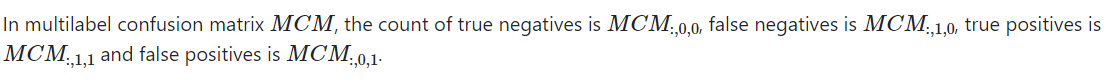

In [ ]:
y_pred=model.predict(X)
print(y_pred)
y_pred = (y_pred>0.5) 

Trying cross validation 

In [ ]:
pip install tensorflow_addons

     |████████████████████████████████| 706kB 8.4MB/s 


In [ ]:
from sklearn.model_selection import KFold
import numpy
import tensorflow_addons as tfa
import tqdm
# fix random seed for reproducibility
seed = 7
numpy.random.seed(seed)
# define 10-fold cross validation test harness
kfold = KFold(n_splits=10, shuffle=True, random_state=seed)
cvscores = []
for train, test in tqdm.tqdm(kfold.split(X, result)):
  # create model
  # accuracy: (tp + tn) / (tp + tn + fp + fn)
  # precision tp / (tp + fp)
  # recall: tp / (tp + fn)
  # f1: 2 tp / (2 tp + fp + fn)


  METRICS = [
        keras.metrics.BinaryAccuracy(name='accuracy'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        #keras.metrics.AUC(name='auc'),
        #keras.metrics.AUC(name='prc', curve='PR'), # precision-recall curve
        tfa.metrics.MatthewsCorrelationCoefficient(num_classes=len(result[0]),name='MatthewsCorrelationCoefficient'), #Trying something new
        #tfa.metrics.HammingLoss(num_classes=len(result[0]),mode='multilabel',name='hamming_loss'),
        #tfa.metrics.F1Score(num_classes=len(result[0]),name='f1_score'),
        #keras.metrics.TruePositives(name='tp'),
        #keras.metrics.FalsePositives(name='fp'),
        #keras.metrics.TrueNegatives(name='tn'),
        #keras.metrics.FalseNegatives(name='fn'), 

  ]

  p=np.sum(result, axis = 0)
  pos=np.sum(p)
  tot= len(result)*len(result[0])
  neg=tot-pos
  initial_bias = np.log([pos/neg])
  output_bias=tf.keras.initializers.Constant(initial_bias)
   
  model = Sequential()
  model.add(Dense(3000, activation='relu', input_shape=(len(X[0]),)))
  model.add(Dense(1000, activation='relu'))
  model.add(Dense(1000, activation='relu'))
  model.add(Dense(1000, activation='relu'))

  model.add(Dense(len(result[0]), activation='sigmoid',bias_initializer=output_bias))


  model.compile(optimizer="Adadelta", loss="binary_crossentropy",metrics=METRICS)
  model.fit(X[train], result[train], epochs=350, batch_size=10, verbose=0)
  # evaluate the model
  scores = model.evaluate(X[test], result[test], verbose=0)
  print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))
  cvscores.append(scores[1] * 100)
print("%.2f%% (+/- %.2f%%)" % (numpy.mean(cvscores), numpy.std(cvscores)))

0it [00:00, ?it/s]

KeyboardInterrupt: ignored

In [ ]:
import keras
reconstructed_model = keras.models.load_model("/content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_5_21_10000_classification")

In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #def data_generator_for_nn(data_points):
  data_points=100
  ip_1=[]
  ip_2=[]
  ip_3=[]
  op_1=[]
  for N in tqdm(range (0,data_points)): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1=Decentralized_multi_agent_paths(n)
    #writing number of vehicles begning their trip in each zone
    for A1 in A1_n1:
      A1_n=[A1]
      Zone_start_trip=[0]*(zone+1)
      Zone_finish_trip=[0]*(zone+1)
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        temp_init=list(a[0])
        #temp=temp_init[0]
        #temp_init[0]=temp_init[1]
        #temp_init[1]=temp
        temp_init=tuple(temp_init)
        init=zones_dictionary.get(temp_init)
        #print(init)
        #print(data[init])
        Zone_start_trip[init]=Zone_start_trip[init]+1

      #writing number of vehicles ending their trip in each zone
      for A1 in A1_n:
        A1_n=[A1]
        #print(a[-1])
        temp_final=list(a[-1])
        #temp=temp_final[0]
        #temp_final[0]=temp_final[1]
        #temp_final[1]=temp
        #temp_final=tuple(temp_final)
        temp_final=tuple(temp_final)
        #print(temp_final)
        final=zones_dictionary.get(temp_final)
        #print(final)
        Zone_finish_trip[final]=Zone_finish_trip[final]+1
      #writing number of vehicles that go to a deck in a zone as intermediate point 
      '''for a in A1_n: 
        count={}
        for item in a:
          count[item]=a.count(item)
         
        for item in a: 
          if count==20 and item !=a[0] and item !=a[-1]:
              temp_rack=item
              #temp=temp_rack[0]
              #temp_rack[0]=temp_rack[1]
              #temp_rack[1]=temp
              #temp_rack=tuple(temp_rack)
              rack= zones_dictionary.get(temp_rack)
              Zone_rack[rack]=Zone_rack[rack]+1'''
      #writing zone busy-ness
      
      Z_n=Zone_business(A1_n)

      ip_1.append(Zone_start_trip)
     
      ip_2.append(Zone_finish_trip)
      
      #ip_3.append(Zone_rack)
     
      op_1.append(Z_n)
 
  list_features_op=[]
  list_features_op.append(ip_1)
  list_features_op.append(ip_2)
  #list_features_op.append(ip_3)
  list_features_op.append(op_1)
  '''df = pd.DataFrame({'ip_1':ip_1,'ip_2':ip_2,'ip_3':ip_3,'op_1':op_1})
  df.to_csv('/content/gdrive/Shareddrives/Winter Simulation 2021/write4.csv',index=False)
  outer_list=list(df)'''

  import pickle
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_testing100_1v_1t.pkl', 'wb') as f:
         pickle.dump(list_features_op, f)
  

100%|██████████| 100/100 [00:06<00:00, 15.56it/s]


In [ ]:
# mlp for regression
from numpy import sqrt
from pandas import read_csv
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
import tensorflow as tf
import pandas as pd
# load the dataset
import pickle
import numpy as np
import keras

pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_testing100_1v_1t.pkl","rb")
emp = pickle.load(pickle_off)



In [ ]:
arr = np.asarray(emp)
X_T=np.array(emp[:2][:][:])
y_T=np.array(emp[2][:][:])
X_T=X_T.reshape(len(X_T[0]),len(X_T[0][0]),len(X_T))
y_T=y_T.reshape(len(y_T),len(y_T[0]))

In [ ]:
#print(emp)
print(len(emp[0][0]))
print(len(emp[0]))
print(len(emp))
print(type(emp))
arr = np.asarray(emp)
#print(arr)
print(arr.shape)
print(len(arr))
print(len(arr[0]))
print(len(arr[0][0]))
#(4, 1000, 352)
  

X_T=np.array(emp[:2][:][:])
y_T=np.array(emp[2][:][:])

print(X_T.shape)
print(y_T.shape)
#X = np.reshape(X, (353,3,1000)).T
X_T=X_T.reshape(len(X_T[0]),len(X_T[0][0]),len(X_T))
y_T=y_T.reshape(len(y_T),len(y_T[0]))
#y = np.reshape(y, (354,1,1000)).T

print(X_T.shape)
print(y_T.shape)
print(len(X_T[0][0]))
print(len(X_T[0]))
print(len(X_T))
#print(X)
# split into train and test datasets
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)
#print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

# determine the number of input features
#n_features = X_train.shape[1]
#n_features = X_train.shape
#n_features_l=n_features[0]
#n_features_b=n_features[1]
#y_len=y_train.shape

arr=y_T
shape = arr.shape
result_T = np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            result_T[x][z] = 1
        else:
          result_T[x][z] = 0
print(result_T)
print(y_T)

1090
200
3
<class 'list'>
(3, 200, 1090)
3
200
1090
(2, 200, 1090)
(200, 1090)
(200, 1090, 2)
(200, 1090)
2
1090
200
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [ ]:
X_T=X_T.reshape(len(X_T),len(X_T[0])*len(X_T[0][0]))
print(X_T.shape)

(200, 2180)


In [ ]:
#print(reconstructed_model.predict(X))
y_pred_T=model.predict(X_T)
print(model.predict(X_T))

[[5.9540778e-08 2.0185510e-06 2.0514091e-03 ... 2.6697246e-04
  3.0932191e-05 6.6926773e-08]
 [7.7890938e-08 1.8490122e-06 1.2476578e-02 ... 5.0541246e-04
  3.5297024e-05 7.8033686e-08]
 [4.5086956e-08 3.0248591e-06 9.1126299e-04 ... 1.9672907e-05
  1.0824554e-06 5.2873606e-08]
 ...
 [1.4693843e-12 2.1044350e-19 2.7630513e-09 ... 1.4304516e-15
  5.6928948e-24 1.2587167e-12]
 [2.7500988e-11 3.2881412e-12 4.9818010e-04 ... 9.9161368e-10
  3.3094438e-17 2.1346626e-11]
 [2.2895678e-12 1.9514362e-19 3.6456711e-16 ... 4.7071140e-17
  6.3841876e-23 2.1088623e-12]]


In [ ]:
y_pred_T = (y_pred_T>0.5) 

In [ ]:
print("Evaluate on test data")
#results = reconstructed_model.evaluate(X, y, batch_size=10)
#results = model.evaluate(X, result, batch_size=10)
resultz = model.evaluate(X_T[1:2], result_T[1:2], batch_size=10)
print(result[1:2])
print(model.predict(X_T[1:2]))
print("test loss, test acc:", resultz)

Evaluate on test data
1/1 [==============================] - 0s 295ms/step - loss: 0.0568 - accuracy: 0.9918 - precision: 0.0000e+00 - recall: 0.0000e+00
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 

In [ ]:
accuracy_T =(1-sum(sum(abs(y_pred_T-result_T))/len(y_pred_T))/len(y_pred_T[0]))*100
#print(len(accuracy))
print(accuracy_T)

96.78073394495412


In [ ]:
import keras
#reconstructed_model = keras.models.load_model("/content/gdrive/Shareddrives/Winter Simulation 2021/my_model_4_16_21_weighted_3")

y_pred_T=model.predict(X_T)

accuracy_T =(1-sum(sum(abs(y_pred_T-result_T))/len(y_pred_T))/len(y_pred_T[0]))*100


from sklearn.metrics import multilabel_confusion_matrix
y_pred_T=model.predict(X_T)
y_pred_T = (y_pred_T>0.5) 
cc=multilabel_confusion_matrix(result_T, y_pred_T)

TN=0
for i in range(0,len(cc)):
  TN=TN+cc[i][0][0]

FN=0
for i in range(0,len(cc)):
  FN=FN+cc[i][1][0]

TP=0
for i in range(0,len(cc)):
  TP=TP+cc[i][1][1]

FP=0
for i in range(0,len(cc)):
  FP=FP+cc[i][0][1]


precision_T=TP/(TP+FP)
recall_T=TP/(TP+FN)
f1_T=2*TP/(2*TP+FP+FN)
print(accuracy_T/100)
print(precision_T)
print(recall_T)
print(f1_T)

0.9479261784707007
0.033497536945812804
0.005600395322022731
0.009596387242449902


SyntaxError: ignored

Incorporating traffic prediction back into path planning 

Step-1 
Calculating time taken to travel in the warehouse -
assuming we know the start and end locations of all the other vehicles that are running in the warehouse.
The number of vehicles can vary between 15-20 

Trying with 5 vehicles that have a particular zone path .


In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #def data_generator_for_nn(data_points):
  data_points=5
  ip_1=[]
  ip_2=[]
  ip_3=[]
  op_1=[]
  for N in tqdm(range (0,data_points)): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1=Decentralized_multi_agent_paths(n)
    #writing number of vehicles begning their trip in each zone
    for A1 in A1_n1:
      A1_n=[A1]
      Zone_start_trip=[0]*(zone+1)
      Zone_finish_trip=[0]*(zone+1)
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        temp_init=list(a[0])
        #temp=temp_init[0]
        #temp_init[0]=temp_init[1]
        #temp_init[1]=temp
        temp_init=tuple(temp_init)
        init=zones_dictionary.get(temp_init)
        #print(init)
        #print(data[init])
        Zone_start_trip[init]=Zone_start_trip[init]+1

      #writing number of vehicles ending their trip in each zone
      for A1 in A1_n:
        A1_n=[A1]
        #print(a[-1])
        temp_final=list(a[-1])
        #temp=temp_final[0]
        #temp_final[0]=temp_final[1]
        #temp_final[1]=temp
        #temp_final=tuple(temp_final)
        temp_final=tuple(temp_final)
        #print(temp_final)
        final=zones_dictionary.get(temp_final)
        #print(final)
        Zone_finish_trip[final]=Zone_finish_trip[final]+1
      #writing number of vehicles that go to a deck in a zone as intermediate point 
      '''for a in A1_n: 
        count={}
        for item in a:
          count[item]=a.count(item)
         
        for item in a: 
          if count==20 and item !=a[0] and item !=a[-1]:
              temp_rack=item
              #temp=temp_rack[0]
              #temp_rack[0]=temp_rack[1]
              #temp_rack[1]=temp
              #temp_rack=tuple(temp_rack)
              rack= zones_dictionary.get(temp_rack)
              Zone_rack[rack]=Zone_rack[rack]+1'''
      #writing zone busy-ness
          
      Z_n=Zone_business(A1_n)

      ip_1.append(Zone_start_trip)
     
      ip_2.append(Zone_finish_trip)
      
      #ip_3.append(Zone_rack)
     
      op_1.append(Z_n)
 
  list_features_op=[]
  list_features_op.append(ip_1)
  list_features_op.append(ip_2)
  #list_features_op.append(ip_3)
  list_features_op.append(op_1)
  '''df = pd.DataFrame({'ip_1':ip_1,'ip_2':ip_2,'ip_3':ip_3,'op_1':op_1})
  df.to_csv('/content/gdrive/Shareddrives/Winter Simulation 2021/write4.csv',index=False)
  outer_list=list(df)'''
  import pickle
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning.pkl', 'wb') as f:
         pickle.dump(list_features_op, f)
        

100%|██████████| 5/5 [00:00<00:00, 17.35it/s]


In [ ]:
#print(len(ip_1))
'''print(sum(ip_1[0]))
print(sum(ip_1[1]))
print(sum(ip_1[2]))
print(sum(ip_1[3]))'''

print(sum(ip_2[0]))
print(sum(ip_2[1]))
print(sum(ip_2[2]))
print(sum(ip_2[3]))

1
1
1
1


In [ ]:
import pandas as pd
# load the dataset
import pickle
import numpy as np
import keras

pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning.pkl","rb")
emp = pickle.load(pickle_off)
print(len(emp[0]))
arr = np.asarray(emp)
X_P=np.array(emp[:2][:][:])
y_P=np.array(emp[2][:][:])
X_P=X_P.reshape(len(X_P[0]),len(X_P[0][0]),len(X_P))
y_P=y_P.reshape(len(y_P),len(y_P[0]))


arr = np.asarray(emp)

  
X_P=np.array(emp[:2][:][:])
y_P=np.array(emp[2][:][:])


X_P=X_P.reshape(len(X_P[0]),len(X_P[0][0]),len(X_P))
y_P=y_P.reshape(len(y_P),len(y_P[0]))


arr=y_P
shape = arr.shape
result_P = np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            result_P[x][z] = 1
        else:
          result_P[x][z] = 0


10


In [ ]:
pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning.pkl","rb")
emp = pickle.load(pickle_off)



In [ ]:

print(result_P)
print(sum(sum(result_P)))

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
282.0


<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
278
[(7, 2), (7, 2), (7, 3), (7, 3), (7, 4), (7, 4), (7, 5), (7, 6), (7, 7), (7, 8), (7, 9), (7, 10), (7, 11), (7, 12), (7, 13), (7, 13), (7, 24), (7, 24), (7, 25), (7, 25), (7, 26), (7, 27), (7, 28), (7, 29), (7, 30), (7, 31), (7, 32), (7, 33), (7, 34), (7, 34), (7, 35), (7, 35), (7, 36), (7, 37), (7, 38), (7, 39), (7, 40), (7, 41), (7, 42), (7, 43), (7, 44), (7, 45), (7, 45), (7, 46), (7, 46), (7, 47), (7, 48), (7, 49), (7, 50), (7, 51), (7, 52), (7, 53), (7, 54), (7, 55), (7, 55), (7, 56), (7, 56), (7, 57), (7, 58), (7, 59), (7, 60), (7, 61), (7, 62), (7, 63), (7, 64), (7, 65), (10, 13), (10, 13), (10, 24), (10, 24), (13, 13), (13, 13), (13, 24), (13, 24), (16, 13), (16, 13), (16, 24), (16, 24), (1

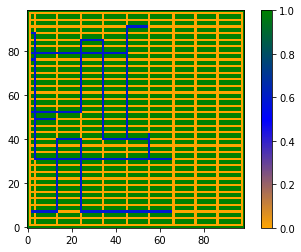

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1

print(sum(Zone_total))

counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=1:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_2=maze1
print(key)
for k in key:
  maze_2[k]=0.6

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_2,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal3.png")

First we try to avoid any zone that has vehicles in it 
Then we try to avoid zones with 2 or more vehicles
if not we try to avoid zones with 3 or more vehicles
Calculate the time taken 
How ?
Factor used-
If 1 other vehicle- 
Trip time is increased to 1.2 times
If 2 other vehicles -
Trip time is increased to 1.4 times
If 3 or more vehicles-
Trip time increased to 2 times 

1.Randomly generate a start and end point \\
2.Find the path using A* \\
3.Check which zones it passes through & calculate the time taken to reach goal using the above matrix \\
4.Try to avoid all other vehicles - look at time taken \\
5.Try to avoid zones with 2 or more vehicles- calculate the time taken \\
6.Try to avoid zones with 3 or more vehicles -calculate the time taken  \\

In [ ]:
pip install tqdm

In [ ]:
  #Step1

  data_points=1
  ip_1_s=[]
  ip_2_f=[]
  op_1_t=[]
  for N in tqdm(range (0,data_points)): 

    n=1
    A1_n1_path=Decentralized_multi_agent_paths(n)
    #writing number of vehicles begning their trip in each zone
    for A1 in A1_n1_path:
      A1_n=[A1]
      Zone_start_trip=[0]*(zone+1)
      Zone_finish_trip=[0]*(zone+1)
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:

        temp_init=list(a[0])

        temp_init=tuple(temp_init)
        init=zones_dictionary.get(temp_init)

        Zone_start_trip[init]=Zone_start_trip[init]+1

      #writing number of vehicles ending their trip in each zone
      for A1 in A1_n:
        A1_n=[A1]

        temp_final=list(a[-1])

        temp_final=tuple(temp_final)
        #print(temp_final)
        final=zones_dictionary.get(temp_final)
        #print(final)
        Zone_finish_trip[final]=Zone_finish_trip[final]+1
      #writing number of vehicles that go to a deck in a zone as intermediate point 
  
      #writing zone busy-ness
          
      Z_n_b=Zone_business(A1_n)

      ip_1_s.append(Zone_start_trip)
     
      ip_2_f.append(Zone_finish_trip)
      
      #ip_3.append(Zone_rack)
     
      op_1_t.append(Z_n)
 
  list_features_op_testcase=[]
  list_features_op_testcase.append(ip_1)
  list_features_op_testcase.append(ip_2)
  #list_features_op.append(ip_3)
  list_features_op_testcase.append(op_1)

  import pickle
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning_test_case.pkl', 'wb') as f:
         pickle.dump(list_features_op_testcase, f)
  with open('/content/gdrive/Shareddrives/Winter Simulation 2021/start_and_end_point_test_case.pkl', 'wb') as f:
         pickle.dump(A1_n1_path, f)

100%|██████████| 1/1 [00:00<00:00, 12.04it/s]


In [ ]:
pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning_test_case.pkl","rb")
emp = pickle.load(pickle_off)


In [ ]:
arr=np.array(op_1_t)
shape = arr.shape
zone_traversed= np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            zone_traversed[x][z] = 1
        else:
          zone_traversed[x][z] = 0


In [ ]:
print(len(zone_traversed))


2


In [ ]:
time_taken_naive_A_Star=sum(sum(zone_traversed))
print(time_taken_naive_A_Star)

38.0


Time taken for the naive A*

In [ ]:
for zone_traversed_counter in zone_traversed:
      for i in range(0,len(zone_traversed[0])):
        if zone_traversed_counter[i]!=0:
            if Zone_total[i]==1:
              time_taken_naive_A_Star=time_taken_naive_A_Star+2
            if Zone_total[i]==2:    
              time_taken_naive_A_Star=time_taken_naive_A_Star+3
            if Zone_total[i]==3:
              time_taken_naive_A_Star=time_taken_naive_A_Star+4

print(time_taken_naive_A_Star)           

204.0


Trying to avoid all other vehicles

[(7, 2), (7, 2), (7, 3), (7, 3), (7, 4), (7, 4), (7, 5), (7, 6), (7, 7), (7, 8), (7, 9), (7, 10), (7, 11), (7, 12), (7, 13), (7, 13), (7, 24), (7, 24), (7, 25), (7, 25), (7, 26), (7, 27), (7, 28), (7, 29), (7, 30), (7, 31), (7, 32), (7, 33), (7, 34), (7, 34), (7, 35), (7, 35), (7, 36), (7, 37), (7, 38), (7, 39), (7, 40), (7, 41), (7, 42), (7, 43), (7, 44), (7, 45), (7, 45), (7, 46), (7, 46), (7, 47), (7, 48), (7, 49), (7, 50), (7, 51), (7, 52), (7, 53), (7, 54), (7, 55), (7, 55), (7, 56), (7, 56), (7, 57), (7, 58), (7, 59), (7, 60), (7, 61), (7, 62), (7, 63), (7, 64), (7, 65), (10, 13), (10, 13), (10, 24), (10, 24), (13, 13), (13, 13), (13, 24), (13, 24), (16, 13), (16, 13), (16, 24), (16, 24), (19, 13), (19, 13), (19, 24), (19, 24), (22, 13), (22, 13), (22, 24), (22, 24), (25, 13), (25, 13), (25, 24), (25, 24), (28, 13), (28, 13), (28, 24), (28, 24), (31, 3), (31, 3), (31, 4), (31, 4), (31, 5), (31, 6), (31, 7), (31, 8), (31, 9), (31, 10), (31, 11), (31, 12), (31, 13), (31, 13), (31, 

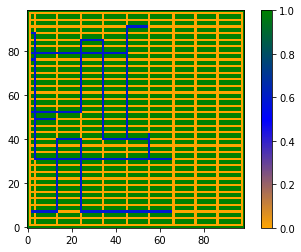

In [ ]:
counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=1:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_2=maze1
print(key)
for k in key:
  maze_2[k]=0.6

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_2,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal1.png")

[(7, 2), (7, 2), (7, 3), (7, 3), (7, 4), (7, 4), (7, 5), (7, 6), (7, 7), (7, 8), (7, 9), (7, 10), (7, 11), (7, 12), (7, 13), (7, 13), (7, 24), (7, 24), (7, 25), (7, 25), (7, 26), (7, 27), (7, 28), (7, 29), (7, 30), (7, 31), (7, 32), (7, 33), (7, 34), (7, 34), (7, 35), (7, 35), (7, 36), (7, 37), (7, 38), (7, 39), (7, 40), (7, 41), (7, 42), (7, 43), (7, 44), (7, 45), (7, 45), (7, 46), (7, 46), (7, 47), (7, 48), (7, 49), (7, 50), (7, 51), (7, 52), (7, 53), (7, 54), (7, 55), (7, 55), (7, 56), (7, 56), (7, 57), (7, 58), (7, 59), (7, 60), (7, 61), (7, 62), (7, 63), (7, 64), (7, 65), (10, 13), (10, 13), (10, 24), (10, 24), (13, 13), (13, 13), (13, 24), (13, 24), (16, 13), (16, 13), (16, 24), (16, 24), (19, 13), (19, 13), (19, 24), (19, 24), (22, 13), (22, 13), (22, 24), (22, 24), (25, 13), (25, 13), (25, 24), (25, 24), (28, 13), (28, 13), (28, 24), (28, 24), (31, 3), (31, 3), (31, 4), (31, 4), (31, 5), (31, 6), (31, 7), (31, 8), (31, 9), (31, 10), (31, 11), (31, 12), (31, 13), (31, 13), (31, 

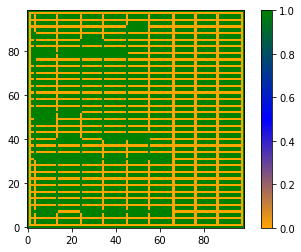

In [ ]:
counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=1:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_2=maze1
print(key)
for k in key:
  maze_2[k]=1

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_2,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal1.png")

In [ ]:
#Start and end positions 
#More specifically - start , shelf, shelf,dock 
init=[]
final=[]
print(A1_n1_path)
for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])

[[(10, 91), (16, 84), (16, 85), (16, 86), (15, 86), (14, 86), (13, 86), (12, 86), (11, 86), (10, 86), (10, 87), (10, 88), (10, 89), (10, 90), (10, 91)], [(10, 90), (10, 89), (10, 88), (10, 87), (10, 86), (10, 85), (10, 84), (10, 83), (10, 82), (10, 81), (10, 80), (10, 79), (10, 78), (10, 77), (10, 76), (10, 75), (10, 74), (10, 73), (10, 72), (10, 71), (10, 70), (10, 69), (10, 68), (10, 67), (10, 66), (10, 65), (10, 64), (10, 63), (10, 62), (10, 61), (10, 60), (10, 59), (10, 58), (10, 57), (10, 56), (10, 55), (10, 54), (10, 53), (10, 52), (10, 51), (10, 50), (10, 49), (10, 48), (10, 47), (10, 46), (10, 45), (10, 44), (10, 43), (10, 42), (10, 41), (10, 40), (10, 39), (10, 38), (10, 37), (10, 36), (10, 35), (10, 34), (10, 33), (10, 32), (10, 31), (10, 30), (10, 29), (10, 28), (10, 27), (10, 26), (10, 25), (10, 24), (10, 23), (10, 22), (10, 21), (10, 20), (10, 19), (10, 18), (10, 17), (10, 16), (10, 15), (10, 14), (10, 13), (10, 12), (10, 11), (10, 10), (10, 9), (10, 8), (10, 7), (10, 6), 

In [ ]:
print(init[0])

(10, 91)


In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #Start and end positions 
  #More specifically - start , shelf, shelf,dock 
  init=[]
  final=[]
  print(A1_n1_path)
  for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])
  #def data_generator_for_nn(data_points):
  data_points=1
  ip_1_avoidall=[]
  ip_2_avoidall=[]
  op_1_avoidall=[]
  for N in range (0,data_points): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1_avoidall=[]
    test_planner = PathPlanner(maze_2, True) 
    print(init)
    start=init[0]
    #print(type(start))
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[0]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a1= test_planner.a_star(start,end) 
    print(type(a1))

    start=init[1]
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[1]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a2= test_planner.a_star(start,end)  
    A1_n1_avoidall.append(a1)
    A1_n1_avoidall.append(a2)
    #print(A1_n1_avoid2)
    #print(len(A1_n1_avoid2))
    if ((len(A1_n1_avoidall[0])!=0 ) and (len(A1_n1_avoidall[1])!=0)):
            #writing number of vehicles begning their trip in each zone
            for A1 in A1_n1_avoidall:
              print(A1)
              A1_n=[A1]
              Zone_start_trip=[0]*(zone+1)
              Zone_finish_trip=[0]*(zone+1)
              #Zone_rack=[0]*(zone+1)
              for a in A1_n1_avoidall:
                print(a)
                #print(a[0])
                temp_init=list(a[0])
                #temp=temp_init[0]
                #temp_init[0]=temp_init[1]
                #temp_init[1]=temp
                temp_init=tuple(temp_init)
                init=zones_dictionary.get(temp_init)
                #print(init)
                #print(data[init])
                Zone_start_trip[init]=Zone_start_trip[init]+1

              #writing number of vehicles ending their trip in each zone
              for A1 in A1_n1_avoidall:
                A1_n=[A1]
                #print(a[-1])
                temp_final=list(a[-1])
                #temp=temp_final[0]
                #temp_final[0]=temp_final[1]
                #temp_final[1]=temp
                #temp_final=tuple(temp_final)
                temp_final=tuple(temp_final)
                #print(temp_final)
                final=zones_dictionary.get(temp_final)
                #print(final)
                Zone_finish_trip[final]=Zone_finish_trip[final]+1
              #writing number of vehicles that go to a deck in a zone as intermediate point 

              #writing zone busy-ness
                  
              Z_n=Zone_business(A1_n1_avoidall)
              
              ip_1_avoidall.append(Zone_start_trip)
            
              ip_2_avoidall.append(Zone_finish_trip)
              
              #ip_3.append(Zone_rack)
            
              op_1_avoidall.append(Z_n)

if ((len(A1_n1_avoidall[0])!=0) and (len(A1_n1_avoidall[1])!=0)):       
          list_features_op_avoidall=[]
          list_features_op_avoidall.append(ip_1_avoidall)
          list_features_op_avoidall.append(ip_2_avoidall)
          #list_features_op.append(ip_3)
          list_features_op_avoidall.append(op_1_avoidall)
if ((len(A1_n1_avoidall[0])==0) or (len(A1_n1_avoidall[1])==0)):
    print("no path found")


[[(10, 91), (16, 84), (16, 85), (16, 86), (15, 86), (14, 86), (13, 86), (12, 86), (11, 86), (10, 86), (10, 87), (10, 88), (10, 89), (10, 90), (10, 91)], [(10, 90), (10, 89), (10, 88), (10, 87), (10, 86), (10, 85), (10, 84), (10, 83), (10, 82), (10, 81), (10, 80), (10, 79), (10, 78), (10, 77), (10, 76), (10, 75), (10, 74), (10, 73), (10, 72), (10, 71), (10, 70), (10, 69), (10, 68), (10, 67), (10, 66), (10, 65), (10, 64), (10, 63), (10, 62), (10, 61), (10, 60), (10, 59), (10, 58), (10, 57), (10, 56), (10, 55), (10, 54), (10, 53), (10, 52), (10, 51), (10, 50), (10, 49), (10, 48), (10, 47), (10, 46), (10, 45), (10, 44), (10, 43), (10, 42), (10, 41), (10, 40), (10, 39), (10, 38), (10, 37), (10, 36), (10, 35), (10, 34), (10, 33), (10, 32), (10, 31), (10, 30), (10, 29), (10, 28), (10, 27), (10, 26), (10, 25), (10, 24), (10, 23), (10, 22), (10, 21), (10, 20), (10, 19), (10, 18), (10, 17), (10, 16), (10, 15), (10, 14), (10, 13), (10, 12), (10, 11), (10, 10), (10, 9), (10, 8), (10, 7), (10, 6), 

In [ ]:
arr=np.array(op_1_avoidall)
shape = arr.shape
zone_traversed_1= np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            zone_traversed_1[x][z] = 1
        else:
          zone_traversed_1[x][z] = 0



time_taken_A_Star_avoidall=sum(sum(zone_traversed_1))
print(time_taken_A_Star_avoidall)

 

148.0


Trying to avoid regions with 2 or more vehicles

<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
278
[(31, 13), (31, 13), (31, 24), (31, 24), (31, 55), (31, 55), (31, 56), (31, 56), (31, 57), (31, 58), (31, 59), (31, 60), (31, 61), (31, 62), (31, 63), (31, 64), (31, 65), (40, 14), (40, 14), (40, 15), (40, 16), (40, 17), (40, 18), (40, 19), (40, 20), (40, 21), (40, 22), (40, 23), (49, 3), (49, 3), (49, 4), (49, 4), (49, 5), (49, 6), (49, 7), (49, 8), (49, 9), (49, 10), (49, 11), (49, 12), (52, 3), (52, 3), (55, 3), (55, 3), (58, 3), (58, 3), (61, 3), (61, 3), (64, 3), (64, 3), (67, 3), (67, 3), (70, 3), (70, 3), (73, 3), (73, 3), (76, 3), (76, 3), (79, 3), (79, 3), (79, 24), (79, 24), (79, 45), (79, 45), (82, 45), (82, 45), (85, 45), (85, 45), (88, 45), (88, 45), (91, 45), (91, 45), (91, 46), (91,

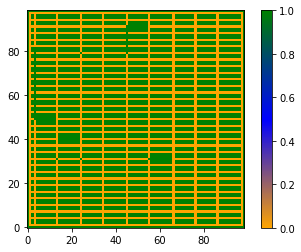

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1

print(sum(Zone_total))

counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=2:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_3=maze1
print(key)
for k in key:
  maze_3[k]=1

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_3,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal2.png")

In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #Start and end positions 
  #More specifically - start , shelf, shelf,dock 
  init=[]
  final=[]
  print(A1_n1_path)
  for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])
  #def data_generator_for_nn(data_points):
  data_points=1
  ip_1_avoid2=[]
  ip_2_avoid2=[]
  op_1_avoid2=[]
  for N in range (0,data_points): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1_avoid2=[]
    test_planner = PathPlanner(maze_3, True) 
    print(init)
    start=init[0]
    #print(type(start))
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[0]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a1= test_planner.a_star(start,end) 
    print(type(a1))

    start=init[1]
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[1]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a2= test_planner.a_star(start,end)  
    A1_n1_avoid2.append(a1)
    A1_n1_avoid2.append(a2)
    #print(A1_n1_avoid2)
    #print(len(A1_n1_avoid2))
    if ((len(A1_n1_avoid2[0])!=0 ) and (len(A1_n1_avoid2[1])!=0)):
            #writing number of vehicles begning their trip in each zone
            for A1 in A1_n1_avoid2:
              print(A1)
              A1_n=[A1]
              Zone_start_trip=[0]*(zone+1)
              Zone_finish_trip=[0]*(zone+1)
              #Zone_rack=[0]*(zone+1)
              for a in A1_n1_avoid2:
                print(a)
                #print(a[0])
                temp_init=list(a[0])
                #temp=temp_init[0]
                #temp_init[0]=temp_init[1]
                #temp_init[1]=temp
                temp_init=tuple(temp_init)
                init=zones_dictionary.get(temp_init)
                #print(init)
                #print(data[init])
                Zone_start_trip[init]=Zone_start_trip[init]+1

              #writing number of vehicles ending their trip in each zone
              for A1 in A1_n1_avoid2:
                A1_n=[A1]
                #print(a[-1])
                temp_final=list(a[-1])
                #temp=temp_final[0]
                #temp_final[0]=temp_final[1]
                #temp_final[1]=temp
                #temp_final=tuple(temp_final)
                temp_final=tuple(temp_final)
                #print(temp_final)
                final=zones_dictionary.get(temp_final)
                #print(final)
                Zone_finish_trip[final]=Zone_finish_trip[final]+1
              #writing number of vehicles that go to a deck in a zone as intermediate point 

              #writing zone busy-ness
                  
              Z_n=Zone_business(A1_n1_avoid2)

              ip_1_avoid2.append(Zone_start_trip)
            
              ip_2_avoid2.append(Zone_finish_trip)
              
              #ip_3.append(Zone_rack)
            
              op_1_avoid2.append(Z_n)

if ((len(A1_n1_avoid2[0])!=0) and (len(A1_n1_avoid2[1])!=0)):       
          list_features_op_avoid2=[]
          list_features_op_avoid2.append(ip_1_avoid2)
          list_features_op_avoid2.append(ip_2_avoid2)
          #list_features_op.append(ip_3)
          list_features_op_avoid2.append(op_1_avoid2)
if ((len(A1_n1_avoid2[0])==0) or (len(A1_n1_avoid2[1])==0)):
    print("no path found")


[[(10, 91), (16, 84), (16, 85), (16, 86), (15, 86), (14, 86), (13, 86), (12, 86), (11, 86), (10, 86), (10, 87), (10, 88), (10, 89), (10, 90), (10, 91)], [(10, 90), (10, 89), (10, 88), (10, 87), (10, 86), (10, 85), (10, 84), (10, 83), (10, 82), (10, 81), (10, 80), (10, 79), (10, 78), (10, 77), (10, 76), (10, 75), (10, 74), (10, 73), (10, 72), (10, 71), (10, 70), (10, 69), (10, 68), (10, 67), (10, 66), (10, 65), (10, 64), (10, 63), (10, 62), (10, 61), (10, 60), (10, 59), (10, 58), (10, 57), (10, 56), (10, 55), (10, 54), (10, 53), (10, 52), (10, 51), (10, 50), (10, 49), (10, 48), (10, 47), (10, 46), (10, 45), (10, 44), (10, 43), (10, 42), (10, 41), (10, 40), (10, 39), (10, 38), (10, 37), (10, 36), (10, 35), (10, 34), (10, 33), (10, 32), (10, 31), (10, 30), (10, 29), (10, 28), (10, 27), (10, 26), (10, 25), (10, 24), (10, 23), (10, 22), (10, 21), (10, 20), (10, 19), (10, 18), (10, 17), (10, 16), (10, 15), (10, 14), (10, 13), (10, 12), (10, 11), (10, 10), (10, 9), (10, 8), (10, 7), (10, 6), 

In [ ]:
arr=np.array(op_1_avoid2)
shape = arr.shape
zone_traversed_1= np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            zone_traversed_1[x][z] = 1
        else:
          zone_traversed_1[x][z] = 0



time_taken_A_Star_avoid2=sum(sum(zone_traversed_1))
#print(time_taken_A_Star_avoid2)


for zone_traversed_1 in op_1_avoid2:
      for i in range(0,len(zone_traversed[0])):
        if zone_traversed_counter[i]!=0:
            if Zone_total[i]==1:
              time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+0.2


print(time_taken_naive_A_Star)   
print(time_taken_A_Star_avoid2)  

65.20000000000005
124.80000000000004


The same can be done for 3 

<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
278
[(49, 3), (49, 3), (52, 3), (52, 3), (55, 3), (55, 3), (58, 3), (58, 3), (61, 3), (61, 3), (64, 3), (64, 3), (67, 3), (67, 3), (70, 3), (70, 3), (73, 3), (73, 3), (76, 3), (76, 3), (79, 3), (79, 3), (50, 3), (50, 3), (51, 3), (53, 3), (53, 3), (54, 3), (56, 3), (56, 3), (57, 3), (59, 3), (59, 3), (60, 3), (62, 3), (62, 3), (63, 3), (65, 3), (65, 3), (66, 3), (68, 3), (68, 3), (69, 3), (71, 3), (71, 3), (72, 3), (74, 3), (74, 3), (75, 3)]


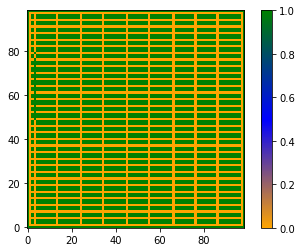

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1

print(sum(Zone_total))

counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=3:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_4=maze1
print(key)
for k in key:
  maze_4[k]=1

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_4,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal2.png")

In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #Start and end positions 
  #More specifically - start , shelf, shelf,dock 
  init=[]
  final=[]
  print(A1_n1_path)
  for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])
  #def data_generator_for_nn(data_points):
  data_points=1
  ip_1_avoid2=[]
  ip_2_avoid2=[]
  op_1_avoid2=[]
  for N in range (0,data_points): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1_avoid2=[]
    test_planner = PathPlanner(maze_4, True) 
    print(init)
    start=init[0]
    #print(type(start))
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[0]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a1= test_planner.a_star(start,end) 
    print(type(a1))

    start=init[1]
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[1]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a2= test_planner.a_star(start,end)  
    A1_n1_avoid2.append(a1)
    A1_n1_avoid2.append(a2)
    #print(A1_n1_avoid2)
    #print(len(A1_n1_avoid2))
    if ((len(A1_n1_avoid2[0])!=0 ) and (len(A1_n1_avoid2[1])!=0)):
            #writing number of vehicles begning their trip in each zone
            for A1 in A1_n1_avoid2:
              print(A1)
              A1_n=[A1]
              Zone_start_trip=[0]*(zone+1)
              Zone_finish_trip=[0]*(zone+1)
              #Zone_rack=[0]*(zone+1)
              for a in A1_n1_avoid2:
                print(a)
                #print(a[0])
                temp_init=list(a[0])
                #temp=temp_init[0]
                #temp_init[0]=temp_init[1]
                #temp_init[1]=temp
                temp_init=tuple(temp_init)
                init=zones_dictionary.get(temp_init)
                #print(init)
                #print(data[init])
                Zone_start_trip[init]=Zone_start_trip[init]+1

              #writing number of vehicles ending their trip in each zone
              for A1 in A1_n1_avoid2:
                A1_n=[A1]
                #print(a[-1])
                temp_final=list(a[-1])
                #temp=temp_final[0]
                #temp_final[0]=temp_final[1]
                #temp_final[1]=temp
                #temp_final=tuple(temp_final)
                temp_final=tuple(temp_final)
                #print(temp_final)
                final=zones_dictionary.get(temp_final)
                #print(final)
                Zone_finish_trip[final]=Zone_finish_trip[final]+1
              #writing number of vehicles that go to a deck in a zone as intermediate point 

              #writing zone busy-ness
                  
              Z_n=Zone_business(A1_n1_avoid2)

              ip_1_avoid2.append(Zone_start_trip)
            
              ip_2_avoid2.append(Zone_finish_trip)
              
              #ip_3.append(Zone_rack)
            
              op_1_avoid2.append(Z_n)
              
if ((len(A1_n1_avoid2[0])!=0) and (len(A1_n1_avoid2[1])!=0)):       
          list_features_op_avoid2=[]
          list_features_op_avoid2.append(ip_1_avoid2)
          list_features_op_avoid2.append(ip_2_avoid2)
          #list_features_op.append(ip_3)
          list_features_op_avoid2.append(op_1_avoid2)
if ((len(A1_n1_avoid2[0])==0) or (len(A1_n1_avoid2[1])==0)):
    print("no path found")


[[(10, 91), (16, 84), (16, 85), (16, 86), (15, 86), (14, 86), (13, 86), (12, 86), (11, 86), (10, 86), (10, 87), (10, 88), (10, 89), (10, 90), (10, 91)], [(10, 90), (10, 89), (10, 88), (10, 87), (10, 86), (10, 85), (10, 84), (10, 83), (10, 82), (10, 81), (10, 80), (10, 79), (10, 78), (10, 77), (10, 76), (10, 75), (10, 74), (10, 73), (10, 72), (10, 71), (10, 70), (10, 69), (10, 68), (10, 67), (10, 66), (10, 65), (10, 64), (10, 63), (10, 62), (10, 61), (10, 60), (10, 59), (10, 58), (10, 57), (10, 56), (10, 55), (10, 54), (10, 53), (10, 52), (10, 51), (10, 50), (10, 49), (10, 48), (10, 47), (10, 46), (10, 45), (10, 44), (10, 43), (10, 42), (10, 41), (10, 40), (10, 39), (10, 38), (10, 37), (10, 36), (10, 35), (10, 34), (10, 33), (10, 32), (10, 31), (10, 30), (10, 29), (10, 28), (10, 27), (10, 26), (10, 25), (10, 24), (10, 23), (10, 22), (10, 21), (10, 20), (10, 19), (10, 18), (10, 17), (10, 16), (10, 15), (10, 14), (10, 13), (10, 12), (10, 11), (10, 10), (10, 9), (10, 8), (10, 7), (10, 6), 

In [ ]:
arr=np.array(op_1_avoid2)
shape = arr.shape
zone_traversed_1= np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            zone_traversed_1[x][z] = 1
        else:
          zone_traversed_1[x][z] = 0



time_taken_A_Star_avoid2=sum(sum(zone_traversed_1))
#print(time_taken_A_Star_avoid2)


for zone_traversed_1 in op_1_avoid2:
      for i in range(0,len(zone_traversed[0])):
        if zone_traversed_counter[i]!=0:
            if Zone_total[i]==1:
              time_taken_A_Star_avoid2=time_taken_A_Star_avoid2+0.2


print(time_taken_naive_A_Star)   
print(time_taken_A_Star_avoid2)  

65.20000000000005
124.80000000000004


And 5 if needed

<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
278
[]


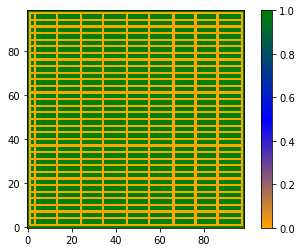

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total=[0]*(zone+1)
trip=-1
for re in result_P:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total[c]=Zone_total[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total[c]=Zone_total[c]+1

print(sum(Zone_total))

counter=-1

key=[]
for z in Zone_total:
  counter=counter+1
  if z>=5:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_5=maze1
print(key)
for k in key:
  maze_5[k]=1

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_5,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal2.png")

In [ ]:
  from tqdm import tqdm
  from google.colab import files
  import random
  import pandas as pd
  import csv 
  import json
  #Start and end positions 
  #More specifically - start , shelf, shelf,dock 
  init=[]
  final=[]
  print(A1_n1_path)
  for A1 in A1_n1_path:
      A1_n=[A1]
      #Zone_rack=[0]*(zone+1)
      for a in A1_n:
        #print(a)
        #print(a[0])
        init.append(a[0])
        final.append(a[-1])
  #def data_generator_for_nn(data_points):
  data_points=1
  ip_1_avoid2=[]
  ip_2_avoid2=[]
  op_1_avoid2=[]
  for N in range (0,data_points): 
    #print(n)
    #n = random. randint(10,15) #randomly generated number between 2 to 20 
    n=1
    A1_n1_avoid2=[]
    test_planner = PathPlanner(maze_5, True) 
    print(init)
    start=init[0]
    #print(type(start))
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[0]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a1= test_planner.a_star(start,end) 
    print(type(a1))

    start=init[1]
    start=list(start)
    temp=start
    start[1]=temp[0]
    start[0]=temp[1]
    end=final[1]
    temp1=end
    end=list(end)
    end[1]=temp1[0]
    end[0]=temp1[1]
    a2= test_planner.a_star(start,end)  
    A1_n1_avoid2.append(a1)
    A1_n1_avoid2.append(a2)
    #print(A1_n1_avoid2)
    #print(len(A1_n1_avoid2))
    if ((len(A1_n1_avoid2[0])!=0 ) and (len(A1_n1_avoid2[1])!=0)):
            #writing number of vehicles begning their trip in each zone
            for A1 in A1_n1_avoid2:
              print(A1)
              A1_n=[A1]
              Zone_start_trip=[0]*(zone+1)
              Zone_finish_trip=[0]*(zone+1)
              #Zone_rack=[0]*(zone+1)
              for a in A1_n1_avoid2:
                print(a)
                #print(a[0])
                temp_init=list(a[0])
                #temp=temp_init[0]
                #temp_init[0]=temp_init[1]
                #temp_init[1]=temp
                temp_init=tuple(temp_init)
                init=zones_dictionary.get(temp_init)
                #print(init)
                #print(data[init])
                Zone_start_trip[init]=Zone_start_trip[init]+1

              #writing number of vehicles ending their trip in each zone
              for A1 in A1_n1_avoid2:
                A1_n=[A1]
                #print(a[-1])
                temp_final=list(a[-1])
                #temp=temp_final[0]
                #temp_final[0]=temp_final[1]
                #temp_final[1]=temp
                #temp_final=tuple(temp_final)
                temp_final=tuple(temp_final)
                #print(temp_final)
                final=zones_dictionary.get(temp_final)
                #print(final)
                Zone_finish_trip[final]=Zone_finish_trip[final]+1
              #writing number of vehicles that go to a deck in a zone as intermediate point 

              #writing zone busy-ness
                  
              Z_n=Zone_business(A1_n1_avoid2)

              ip_1_avoid2.append(Zone_start_trip)
            
              ip_2_avoid2.append(Zone_finish_trip)
              
              #ip_3.append(Zone_rack)
            
              op_1_avoid2.append(Z_n)
              
if ((len(A1_n1_avoid2[0])!=0) and (len(A1_n1_avoid2[1])!=0)):       
          list_features_op_avoid2=[]
          list_features_op_avoid2.append(ip_1_avoid2)
          list_features_op_avoid2.append(ip_2_avoid2)
          #list_features_op.append(ip_3)
          list_features_op_avoid2.append(op_1_avoid2)
if ((len(A1_n1_avoid2[0])==0) or (len(A1_n1_avoid2[1])==0)):
    print("no path found")


[[(10, 91), (16, 84), (16, 85), (16, 86), (15, 86), (14, 86), (13, 86), (12, 86), (11, 86), (10, 86), (10, 87), (10, 88), (10, 89), (10, 90), (10, 91)], [(10, 90), (10, 89), (10, 88), (10, 87), (10, 86), (10, 85), (10, 84), (10, 83), (10, 82), (10, 81), (10, 80), (10, 79), (10, 78), (10, 77), (10, 76), (10, 75), (10, 74), (10, 73), (10, 72), (10, 71), (10, 70), (10, 69), (10, 68), (10, 67), (10, 66), (10, 65), (10, 64), (10, 63), (10, 62), (10, 61), (10, 60), (10, 59), (10, 58), (10, 57), (10, 56), (10, 55), (10, 54), (10, 53), (10, 52), (10, 51), (10, 50), (10, 49), (10, 48), (10, 47), (10, 46), (10, 45), (10, 44), (10, 43), (10, 42), (10, 41), (10, 40), (10, 39), (10, 38), (10, 37), (10, 36), (10, 35), (10, 34), (10, 33), (10, 32), (10, 31), (10, 30), (10, 29), (10, 28), (10, 27), (10, 26), (10, 25), (10, 24), (10, 23), (10, 22), (10, 21), (10, 20), (10, 19), (10, 18), (10, 17), (10, 16), (10, 15), (10, 14), (10, 13), (10, 12), (10, 11), (10, 10), (10, 9), (10, 8), (10, 7), (10, 6), 

In [ ]:
arr=np.array(op_1_avoid2)
shape = arr.shape
zone_traversed_1= np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            zone_traversed_1[x][z] = 1
        else:
          zone_traversed_1[x][z] = 0



time_taken_A_Star_avoid2=sum(sum(zone_traversed_1))
#print(time_taken_A_Star_avoid2)





print(time_taken_naive_A_Star)   
print(time_taken_A_Star_avoid2)  

65.20000000000005
118.0


Make intersection zones of their own
trip assumption remains same
5 vehicles - 1,2,3,or 4, 5


using the prediction model

In [ ]:
from numpy import sqrt
from pandas import read_csv
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
import tensorflow as tf
import pandas as pd
# load the dataset
import pickle
import numpy as np
import keras

pickle_off = open("/content/gdrive/Shareddrives/Winter Simulation 2021/data_for_pathplanning.pkl","rb")
emp = pickle.load(pickle_off)

In [ ]:
arr = np.asarray(emp)
X_T=np.array(emp[:2][:][:])
y_T=np.array(emp[2][:][:])
X_T=X_T.reshape(len(X_T[0]),len(X_T[0][0]),len(X_T))
y_T=y_T.reshape(len(y_T),len(y_T[0]))

In [ ]:
#print(emp)
print(len(emp[0][0]))
print(len(emp[0]))
print(len(emp))
print(type(emp))
arr = np.asarray(emp)
#print(arr)
print(arr.shape)
print(len(arr))
print(len(arr[0]))
print(len(arr[0][0]))
#(4, 1000, 352)
  

X_T=np.array(emp[:2][:][:])
y_T=np.array(emp[2][:][:])

print(X_T.shape)
print(y_T.shape)
#X = np.reshape(X, (353,3,1000)).T
X_T=X_T.reshape(len(X_T[0]),len(X_T[0][0]),len(X_T))
y_T=y_T.reshape(len(y_T),len(y_T[0]))
#y = np.reshape(y, (354,1,1000)).T

print(X_T.shape)
print(y_T.shape)
print(len(X_T[0][0]))
print(len(X_T[0]))
print(len(X_T))
#print(X)
# split into train and test datasets
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)
#print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

# determine the number of input features
#n_features = X_train.shape[1]
#n_features = X_train.shape
#n_features_l=n_features[0]
#n_features_b=n_features[1]
#y_len=y_train.shape

arr=y_T
shape = arr.shape
result_T = np.zeros(shape)
for x in range(0, shape[0]):
  for z in range(0, shape[1]):
        if arr[x][z] >= 1:
            result_T[x][z] = 1
        else:
          result_T[x][z] = 0
print(result_T)
print(y_T)

1090
10
3
<class 'list'>
(3, 10, 1090)
3
10
1090
(2, 10, 1090)
(10, 1090)
(10, 1090, 2)
(10, 1090)
2
1090
10
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [ ]:
X_T=X_T.reshape(len(X_T),len(X_T[0])*len(X_T[0][0]))
print(X_T.shape)

(10, 2180)


In [ ]:
y_pred_T=model.predict(X_T)

<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
<class 'numpy.ndarray'>
1090
0
[]


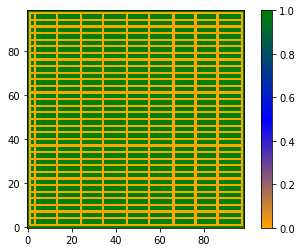

In [ ]:
import numpy as np
filein = "/content/gdrive/Shareddrives/Winter Simulation 2021/Layout_updated_2021 (1).csv"
data = np.loadtxt(open(filein, "rb"), delimiter=",")
#print(data)
maze1=np.array(data)
maze1 = np.where(maze1 == 100, 1, maze1)
maze1 = np.where(maze1 == -1, 1, maze1)
maze1 = np.where(maze1 == 200, 1, maze1)
maze1 = np.where(maze1 == 50, 0, maze1)


Zone_total_Pred=[0]*(zone+1)
trip=-1
for re in y_pred_T:
      #print(re)
      print(type(re))
      print(len(re))
      c=-1
      trip=trip+1
      if (trip/2)==0:
        Zone_temp=[0]*(zone+1)
        for r in re:
            c=c+1
            #print(r)
            if r==1:
                Zone_total_Pred[c]=Zone_total_Pred[c]+1
                Zone_temp[c]=1
      if (trip/2)!=0:
        for r in re:
            c=c+1
            if r==1:
              if (Zone_temp[c]!=1):
                Zone_total_Pred[c]=Zone_total_Pred[c]+1

print(sum(Zone_total_Pred))

counter=-1

key=[]
for z in Zone_total_Pred:
  counter=counter+1
  if z>=1:
     #val=zones_dictionary.get(a)
     key.append(next(((k,i) for (k,i) in zones_dictionary if zones_dictionary[(k,i)] == counter), None))
     #zones_dictionary.keys()[zones_dictionary.values(counter)]
     for i in zones_dictionary:
       #print(i)
       if zones_dictionary[i]==counter:
         key.append(i)


maze_6=maze1
print(key)
for k in key:
  maze_2[k]=0.6

from matplotlib import pyplot
import matplotlib as mpl

fig = pyplot.figure(2)

cmap2 = mpl.colors.LinearSegmentedColormap.from_list('my_colormap',
                                           ['orange','blue','green'],
                                           256)

img2 = pyplot.imshow(maze_6,interpolation='nearest',
                    cmap = cmap2,
                    origin='lower')

pyplot.colorbar(img2,cmap=cmap2)

fig.savefig("/content/gdrive/Shareddrives/Winter Simulation 2021/image_test_more_than_orequal3.png")

Risk of collission etc
Arent measured by the simulation method
They can be the advantage


Abstract-
Introduction - 
Motivation 
Innovation 
Explain the problem

Introduction culminates to the problem
Literature review section- can be short
More papers , less details
10 or so very recent related references, takes up 1/2 or 3/4th of the page
Methodology section 
System description 
Technical methodology 
implementation - setting up and determining models
Patricks paper - reference
Images-
ground truth 
predicted path 
A* path 
Alternate path 
Experimental section 
Conclusion and future work 